# Сверточные сети

Разнообразие слоев для сверточной сети опирается на понятие тензор и его обработку в средах типа TensorFlow.

Тензор - объект линейной алгебры, линейно преобразующий элементы одного линейного пространства в элементы другого

Ранг тензора — это количество его индексов

Сверточные нейронные сети - это нейронные сети приспособленные впервую очередь для задач распознования образов. В их основе лежат работы в области изучения зрительной коры головного мозга. Их отличительная черта - добавление сверточных и пуллинговых слоев в архитектуру нейронной сети


## 1.1 Сверточный слой

Посмотрим как работает наложение фильтра на изображение

Прочитаем изображение и следаем его свертку с некоторым фильтром (воспользуемся средствами OpenCV (cv2) и scipy)




In [ ]:
import cv2
import numpy as np
from scipy import datasets

i_mage = datasets.ascent().astype(np.float64)

Исходное изображение

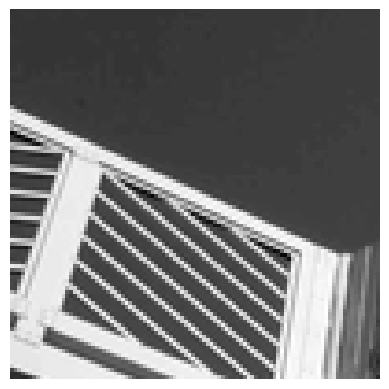

In [ ]:
import matplotlib.pyplot as plt

plt.grid(False)
plt.gray()
plt.axis("off")
plt.imshow(i_mage[50:150, :100])
plt.show()

Создадим фильтр

In [ ]:
i_transformed = np.copy(i_mage)
size_x = i_transformed.shape[0]
size_y = i_transformed.shape[1]

# Фильтры края.

# Разные фильтры.
filter = [[0, 1, 0], [1, -4, 1], [0, 1, 0]]

# Много разных
# filter = [ [-1, -2, -1], [0, 0, 0], [1, 2, 1]]
# filter = [ [-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]

# зададим вес для свертки
weight = 1

Наложим фильтр на изображение, используем скользящее окно и поэлементное вычисление свертки

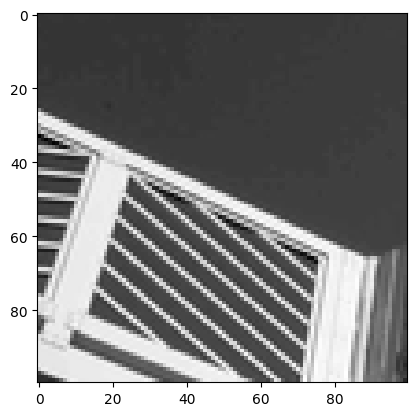

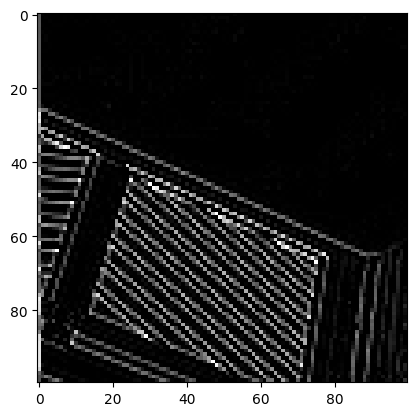

In [ ]:
for x in range(1, size_x - 1):
    for y in range(1, size_y - 1):
        # convolution
        convolution = 0.0
        convolution = convolution + (i_mage[x - 1, y - 1] * filter[0][0])
        convolution = convolution + (i_mage[x, y - 1] * filter[0][1])
        convolution = convolution + (i_mage[x + 1, y - 1] * filter[0][2])
        convolution = convolution + (i_mage[x - 1, y] * filter[1][0])
        convolution = convolution + (i_mage[x, y] * filter[1][1])
        convolution = convolution + (i_mage[x + 1, y] * filter[1][2])
        convolution = convolution + (i_mage[x - 1, y + 1] * filter[2][0])
        convolution = convolution + (i_mage[x, y + 1] * filter[2][1])
        convolution = convolution + (i_mage[x + 1, y + 1] * filter[2][2])
        convolution = convolution * weight
        if convolution < 0:
            convolution = 0
        if convolution > 255:
            convolution = 255
        i_transformed[x, y] = convolution

# Plot исходное изображение
plt.gray()
plt.grid(False)
plt.imshow(i_mage[50:150, :100])
# plt.axis('off')
plt.show()
# Plot фильтрованное изображение
plt.gray()
plt.grid(False)
plt.imshow(np.abs(i_transformed[50:150, :100]))
# plt.axis('off')
plt.show()

Построим модель слоя при прямом распространении сигнала через сверточный слой

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# прямое распространение
def ConvLayer_Forward(Tensor=None, W=None, b=None):
    # на вход:
    # Tensor  - входное изображение
    # W - значения весов нейронов (ядра-фильтры)
    # b - значение сдвигов нейронов
    # на выходе: Output - результат свертки (число каналов = числу фильтров(ядер))

    Output = []
    # print(Tensor.shape)

    iw = 0
    # проходимся по каждому из фильтров
    for f in W:
        print(f)
        output = np.zeros(Tensor.shape[:-1])
        # print(output.shape, f.shape)
        # проходимся по фильтрам
        for y in range(Tensor.shape[0] - f.shape[0]):
            for x in range(Tensor.shape[1] - f.shape[1]):
                sum = 0
                sum = b[iw]  # сразу прибавляем смещение
                sum = sum + np.sum(
                    np.dot(f, Tensor[y : y + f.shape[0], x : x + f.shape[1]])
                )

                output[y, x] = (
                    sum.copy()
                )  # записываем результат свёртки в выходной тензор
        # print(x,y)
        Output.append(output.copy())
        iw += 1
    Output = np.array(Output)
    return Output

Построим модель слоя при обратном распространении сигнала через слой

In [ ]:
def Convolution_Backprop(delta_conv_prev=None, conv_input=None, K=None):
    # входы:
    # delta_conv_prev - ошибка со следующего слоя
    # conv_input - входное изображение на слое
    # K - текущее значение фильтров(ядер - нейроных весов) слоя
    # на выходе
    # dK - поправки для фильтров (без скорости обучения)
    # db - поправки для сдвигов нейрона без скорости обучения
    # I_back - ошибку на входе в сверточный слой
    # Backpropagation

    (n_f, n_c, _) = K.shape
    (_, orig_dim, _) = conv_input.shape
    # строим размер
    dout = np.zeros(conv_input.shape)
    dK = np.zeros(K.shape)
    dbias = np.zeros((n_f, 1))
    iw = 0
    for f in K:
        # по каналам
        out_y = 0
        for y in range(conv_input.shape[0] - f.shape[0]):
            out_x = 0
            for x in range(conv_input.shape[1] - f.shape[1]):
                # градиент loss по всем текущим точкам
                dK[iw, :, :] += (
                    delta_conv_prev[iw, y, x]
                    * conv_input[y : y + f.shape[0], x : x + f.shape[1], 0]
                )
                # print(np.sum(np.abs(delta_conv_prev[iw, y, x] * conv_input[ y:y+f.shape[0], x:x+f.shape[1],:])))
                # перенос loss через этот слой
                dout[y, x, :] += np.sum(delta_conv_prev[iw, y, x] * f)

        # loss gradient of the bias
        dbias[iw] = np.sum(delta_conv_prev[iw])
        iw += 1

    return dout, dK, dbias


Создадим 10 фильтров(ядер-нейронов) сверточного слоя как случайные равномерные с размером 3х3 , создадим изображение (белый прямоугольник на черном фоне) и примени к этому изображению сверточный слой

In [ ]:
K = np.random.random((10, 3, 3)) * 10 - 5
b = np.random.random(10) * 0.1

K[0, :, 0] = -1
K[0, :, 2] = 1
K[0, :, 1] = 0
K[0, 1, :] = K[0, 1, :] * 2

I = np.zeros((100, 100, 1))

I[20:40, 30:70, 0] = 1

Делаем прямой проход и вычисляем 10 изображений результатов

[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
[[ 3.15361065 -3.46875742  0.58644955]
 [ 2.2723217   0.01978996 -1.70470488]
 [-0.7707479  -1.11419758  4.50235351]]
[[ 1.23850687 -2.41100735 -0.98180944]
 [ 0.33473281  0.57915236 -0.57705875]
 [ 2.36260402  0.60067031 -2.37473382]]
[[-2.09432508 -2.72102535 -2.97761333]
 [-2.31791165 -4.87588904  0.75098855]
 [-4.51016248 -3.16031384 -2.18051642]]
[[-3.17558385  2.59721314 -1.85874784]
 [ 4.81409555 -3.80144992  0.6672986 ]
 [-1.09485815  2.33369093 -0.85392862]]
[[-2.52747388  0.40696816  0.38811176]
 [-2.83508998  0.9561564   2.0099491 ]
 [ 2.64849684 -0.7973506  -4.60129293]]
[[-1.46441375  2.08417504  4.0501074 ]
 [ 4.53764596  2.92669628 -2.46329599]
 [-3.73871995 -3.02794766 -3.74615573]]
[[-4.89489751 -4.05830491 -1.7120031 ]
 [-3.5481223   0.97351889 -4.20483692]
 [ 4.83046828 -1.64470236 -1.25658673]]
[[ 4.28893077 -0.53436764  3.13684198]
 [-0.93414048  1.94203935 -1.31502898]
 [-3.66976337  0.19716375  0.10596956]]
[[-1.77697

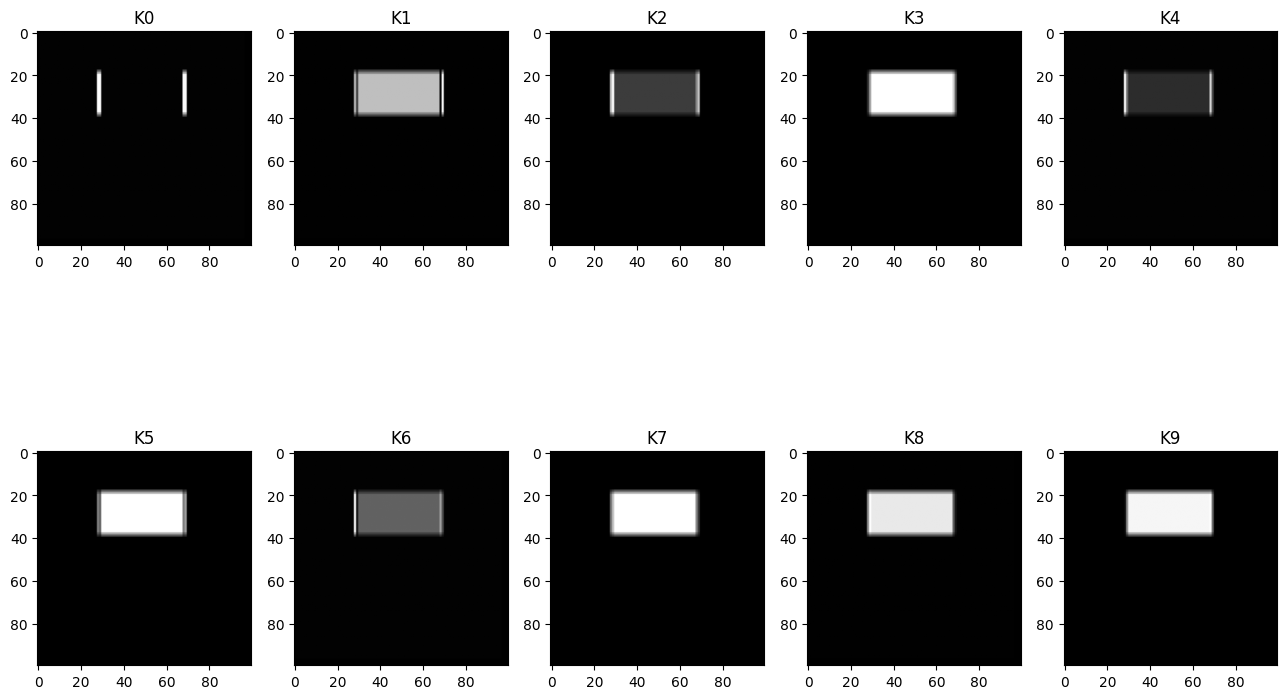

In [ ]:
I_ = ConvLayer_Forward(Tensor=I, W=K, b=b)

plt.figure(figsize=(16, 10))
for i in [0, 1, 2, 3, 4]:
    for j in [0, 1]:
        plt.subplot(2, 5, i + j * 5 + 1)
        plt.title("K" + str(i + j * 5))
        plt.imshow(np.abs((I_[i + j * 5, :, :]) / np.max(np.abs(I_[i + j * 5, :, :]))))

plt.show()


Делаем обратный проход:
 создаем истиный результат (It) и находим дельту Loss_e (ошибку слоя на выходе (она должна прийти из следующего за текущим слоя ))

 Вернем:

 - dK - поправки для фильтров (без скорости обучения)
 - db - поправки для сдвигов нейрона без скорости обучения
 - I_back - ошибку на входе в сверточный слой

In [ ]:
It = I_ + np.random.random((10, 100, 100)) * 1 - 0.5

Loss_e = It - I_

I_back, dK, db = Convolution_Backprop(delta_conv_prev=Loss_e, conv_input=I, K=K)

In [ ]:
dK

array([[[  2.20702087,   2.15109392,   3.81517111],
        [  0.50000903,   0.52385793,   1.57322053],
        [  0.245235  ,   0.31998128,   1.85656398]],

       [[ -3.39913584,  -1.18937613,   1.26367926],
        [ -9.58506328,  -8.25386774,  -6.22318825],
        [ -2.58415873,  -1.53016698,   0.43396479]],

       [[ 13.60700764,  16.21838008,  14.59743481],
        [ 16.24789008,  18.44428121,  16.13315359],
        [ 16.96757175,  18.95063577,  16.31607578]],

       [[  9.21953179,  10.63490653,   7.65491898],
        [  9.35830177,  10.97501137,   8.01938934],
        [ 10.23587663,  12.54893764,  10.19925766]],

       [[  6.14584064,   3.99505157,   1.69948003],
        [  6.03820432,   3.837539  ,   2.25759984],
        [  5.84136808,   4.3163454 ,   1.75365303]],

       [[-19.65799576, -21.72899827, -18.83589151],
        [-20.24653145, -22.22792952, -18.82621733],
        [-18.47273717, -21.39902983, -17.51558756]],

       [[  8.82788522,   9.47915705,  11.03445389],


In [ ]:
db

array([[ 37.78002843],
       [-10.50097532],
       [  6.34479268],
       [ 38.24378148],
       [  8.49760878],
       [ -1.59560319],
       [ 38.38958128],
       [-36.4754169 ],
       [ 20.52730478],
       [ 19.50320449]])

In [ ]:
I_back[:40, :40, 0]

array([[ -9.17849687, -17.92260247, -18.69492908, ..., -13.66705657,
         -3.52219094,  -5.68706235],
       [ -0.64797775, -10.50330756,   6.72995697, ...,   6.66235861,
          7.85612314, -22.91166608],
       [ 17.43503111,  -3.50138601, -11.30544646, ...,   2.49891095,
         18.7575993 ,   4.59570885],
       ...,
       [ -3.97907029,  -1.39485116,  -5.79425709, ..., -14.81644891,
          8.48476171, -10.62029993],
       [ -0.79898911,   4.22858237,   2.7468657 , ...,   0.39714495,
        -17.37725707,  -4.14177451],
       [  5.46701725,   9.55660659, -12.14614505, ..., -21.49962444,
          0.4880103 ,  12.15433699]], shape=(40, 40))

результат обратного прохода по свертке

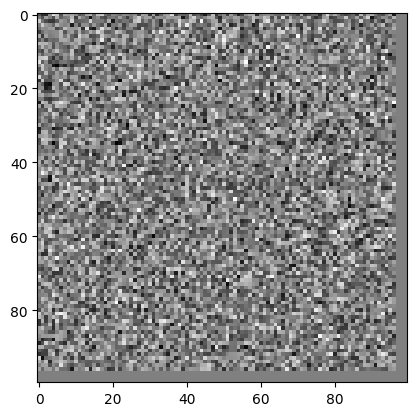

In [ ]:
plt.imshow(I_back[:, :, 0] / np.max(I_back + 1))
plt.show()


## 1.2. Слой Пулинга

Посмотрим на пулинг с точки зрения обработки изображений

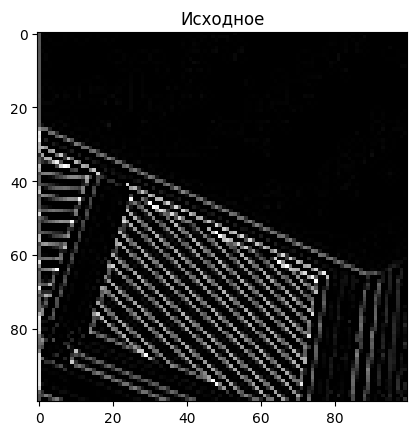

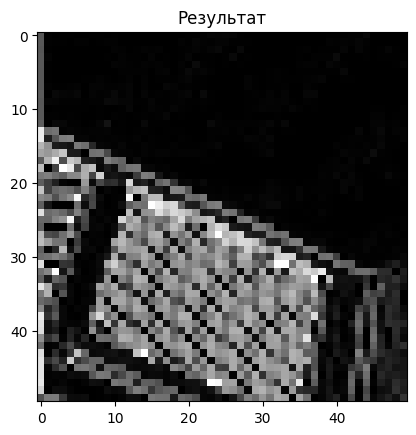

In [ ]:
new_x = int(size_x / 2)
new_y = int(size_y / 2)
# создаем изображение для накопрения результатов пулинга
newImage = np.zeros((new_x, new_y))
for x in range(0, size_x, 2):
    for y in range(0, size_y, 2):
        # вычисляем один пиксель
        pixels = []
        pixels.append(i_transformed[x, y])
        pixels.append(i_transformed[x + 1, y])
        pixels.append(i_transformed[x, y + 1])
        pixels.append(i_transformed[x + 1, y + 1])
        newImage[int(x / 2), int(y / 2)] = max(pixels)

# исходное
plt.gray()
plt.grid(False)
plt.imshow(i_transformed[50:150, :100])
plt.title("Исходное")
# plt.axis('off')
plt.show()

# Plot результирующее изображение
plt.gray()
plt.grid(False)
plt.imshow(newImage[25:75, :50])
plt.title("Результат")
# plt.axis('off')
plt.show()

Содздадим модель слоя пулинга при прямом проходе

In [ ]:
def Maxpool_Forward(image, k=2, s=2):
    # kernel size - k
    # stride  - s
    # image - входное изображение
    h_prev, w_prev, n_c = image.shape

    # Определим размер выхода слоя
    h = int((h_prev - k) / s) + 1
    w = int((w_prev - k) / s) + 1

    # создадим выходной тензор.
    MaxPool_ = np.zeros((h, w, n_c))

    # скользим по каналам тензора
    for i in range(n_c):
        y = out_y = 0
        # вертикально
        while y + k <= h_prev:
            x = out_x = 0
            # горизонтально
            while x + k <= w_prev:
                # выбрали максимальное значение
                MaxPool_[out_y, out_x, i] = np.max(image[y : y + k, x : x + k, i])
                x += s
                out_x += 1
            y += s
            out_y += 1
    return MaxPool_

Обратьный проход по пулингу

In [ ]:
def Maxpool_Backprop(I_pool_inp=None, delta_pool_prev=None, k=2, s=2):
    # kernel size - k
    # stride  - s

    h_prev, w_prev, n_c = I_pool_inp.shape
    h_, w_, n_d = delta_pool_prev.shape
    # Определим размер выхода слоя
    h = h_prev
    w = w_prev

    # создадим выходной тензор.
    dout = np.zeros((h_prev, w_prev, n_c))

    # скользим по каналам тензора
    for i in range(n_c):
        y = out_y = 0
        # вертикально

        while out_y + k <= h_prev:
            x = out_x = 0
            # горизонтально

            while out_x + k <= w_prev:
                # выбрали максимальное значение (берем его координаты в выдленном куске входной картинки
                imax = np.argmax(I_pool_inp[out_y : out_y + k, out_x : out_x + k, i])
                # print(imax)
                # maxPooling
                if np.isscalar(imax):
                    ind = np.unravel_index(
                        np.argmax(I_pool_inp[out_y : out_y + k, out_x : out_x + k, i]),
                        I_pool_inp[out_y : out_y + k, out_x : out_x + k, i].shape,
                    )
                    # добавляем дельту только в максимум (если средний, то добавим всем элементам без поиска максимума во входной картинке
                    dout[out_y + ind[0], out_x + ind[1], i] += delta_pool_prev[y, x, i]
                    # print(out_y+ind[0], out_x+ind[1],dout[out_y+ind[0], out_x+ind[1], i] )
                # AveragPooling
                # dout[out_y:out_y+k, out_x:out_x+k, i]  = delta_pool_prev[y,x]
                # SumPooling
                # dout[out_y:out_y+k, out_x:out_x+k, i]  = delta_pool_prev[y,x]/k**2
                x += 1
                out_x += s
            y += 1
            out_y += s
    return dout

Посмотрим как сработал пулинг

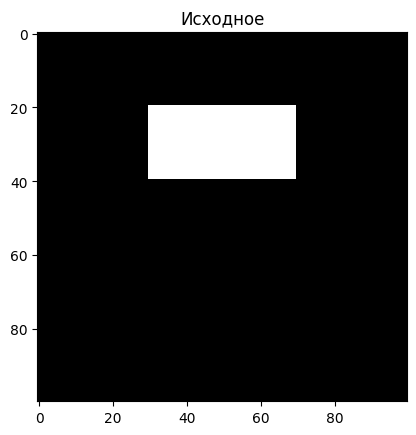

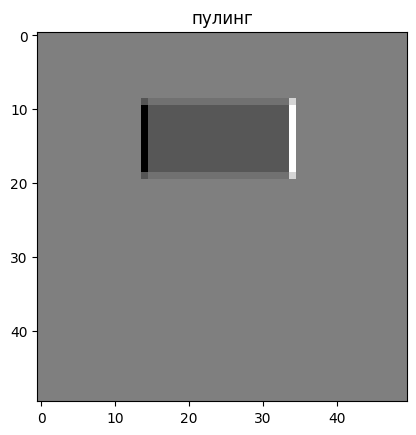

In [ ]:
I = np.zeros((100, 100, 1))

I[20:40, 30:70, 0] = 1

I_max_pool = Maxpool_Forward(I_[2, :, :].reshape((100, 100, 1)), k=2, s=2)

plt.imshow(I[:, :, 0])
plt.title("Исходное")
plt.show()

plt.imshow(I_max_pool[:, :, 0] / np.max(I_max_pool + 1))
plt.title("пулинг")
plt.show()

Запустим обратное распространение по пулингу

In [ ]:
It = I_max_pool.reshape((50, 50, 1)) + np.random.random((50, 50, 1)) * 1 - 0.5

Loss_e = It - I_max_pool

dI_back = Maxpool_Backprop(
    I_pool_inp=I_[0, :, :].reshape((100, 100, 1)), delta_pool_prev=Loss_e, k=2, s=2
)

Посмотрим как сработало

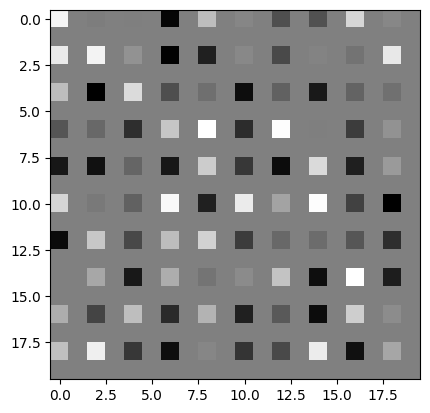

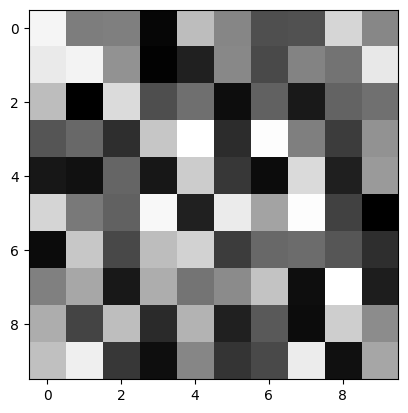

In [ ]:
plt.imshow(dI_back[:20, :20, 0] / np.max(dI_back + 1))
plt.show()
plt.imshow(Loss_e[:10, :10, 0] / np.max(Loss_e + 1))
plt.show()


## 1.3. Слой обратной свертки

In [ ]:
import tensorflow as tf


def test_conv2d_transpose():
    # входной пакет = (1, 2, 2, 1) -> (batch_size, height, width, channels) - 2x2x1 одна картинка в пакете
    x = tf.constant(np.array([[[[1], [2]], [[3], [4]]]]), tf.float32)

    # форма = (3, 3, 1, 1) -> (height, width, input_channels, output_channels) - 3x3x1 фильтр
    f = tf.constant(
        np.array([[[[1]], [[1]], [[1]]], [[[1]], [[1]], [[1]]], [[[1]], [[1]], [[1]]]]),
        tf.float32,
    )

    conv = tf.nn.conv2d_transpose(
        x, f, output_shape=(1, 4, 4, 1), strides=[1, 2, 2, 1], padding="SAME"
    )
    # для TF 1.14
    # with tf.Session() as session:
    #    result = session.run(conv)
    # TF 2.0
    result = conv.numpy()
    return result

Посмотрим результат обратной свертки

In [ ]:
res = test_conv2d_transpose()
res.reshape((4, 4))


array([[ 1.,  1.,  3.,  2.],
       [ 1.,  1.,  3.,  2.],
       [ 4.,  4., 10.,  6.],
       [ 3.,  3.,  7.,  4.]], dtype=float32)

## 1.4 Пакетная нормализация

In [ ]:
# необходимые пакеты
import matplotlib.pyplot as plt
import seaborn

import numpy as np
import pandas as pd

https://kratzert.github.io/2016/02/12/understanding-the-gradient-flow-through-the-batch-normalization-layer.html

In [ ]:
def batchnorm_forward(x, gamma, beta, eps):
    N, D = x.shape

    # 1: вычислим среднее
    mu = 1.0 / N * np.sum(x, axis=0)
    # 2: центрируем тензоры по каждому признаку
    xmu = x - mu
    # 3: считаем квадрат отклонений
    sq = xmu**2
    # 4: дисперсия
    var = 1.0 / N * np.sum(sq, axis=0)
    # 5: добавим еще чуть-чуть для корректных расчетов потом и найдем корень
    sqrtvar = np.sqrt(var + eps)
    # 6: определим обратную величину к сигма
    ivar = 1.0 / sqrtvar
    # 7: вычислим новую варианцию
    xhat = xmu * ivar
    # 8: поднимаем уровень по Гамме
    gammax = gamma * xhat
    # 9: выход модели
    out = gammax + beta
    # сохраним все, что сделали
    cache = (xhat, gamma, xmu, ivar, sqrtvar, var, eps, mu)
    return out, cache

In [ ]:
def batchnorm_backward(dout, cache):
    # достаем из cache все данные о том как был обработан тензор
    xhat, gamma, xmu, ivar, sqrtvar, var, eps, mu = cache

    # gвычисляем размер входа и выхода
    N, D = dout.shape

    # 9 : вычисляем производные для параметров (бетта )
    dbeta = np.sum(dout, axis=0)
    # 8 : Вычислим производную для гаммы
    dgammax = dout
    dgamma = np.sum(dgammax * xhat, axis=0)
    dxhat = dgammax * gamma

    # 7 :
    divar = np.sum(dxhat * xmu, axis=0)
    dxmu1 = dxhat * ivar

    # 6 :
    dsqrtvar = -1.0 / (sqrtvar**2) * divar

    # 5 :
    dvar = 0.5 * 1.0 / np.sqrt(var + eps) * dsqrtvar

    # 4 :
    dsq = 1.0 / N * np.ones((N, D)) * dvar

    # 3 :
    dxmu2 = 2 * xmu * dsq

    # 2 :
    dx1 = dxmu1 + dxmu2
    dmu = -1 * np.sum(dxmu1 + dxmu2, axis=0)

    # 1 :
    dx2 = 1.0 / N * np.ones((N, D)) * dmu

    # 0 :
    dx = dx1 + dx2

    return dx, dgamma, dbeta


In [ ]:
N = 10
D = 3

tensor_input = np.random.random((N, D)) / 2
tensor_input[(N // 2) :, :] += 0.5
print(tensor_input[0, :], tensor_input[-1, :])

[0.06266405 0.12607776 0.25350356] [0.84535275 0.73049949 0.61968964]


In [ ]:
tensor_out, cache = batchnorm_forward(tensor_input, 0.3, 0.5, 0.001)
print("до: ", tensor_input[0, :], "    после: ", tensor_out[0, :])
print("до: ", tensor_input[-1, :], "    после: ", tensor_out[-1, :])
print("mu: ", cache[7], "\nsigma: ", cache[5])

до:  [0.06266405 0.12607776 0.25350356]     после:  [-0.054577    0.11334894  0.21117006]
до:  [0.84535275 0.73049949 0.61968964]     после:  [0.95292991 0.73892117 0.74571094]
mu:  [0.49349102 0.49965621 0.45136589] 
sigma:  [0.0533156  0.08301711 0.04123615]


In [ ]:
dout = np.random.random((N, D)) / 10
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
print("dx: ", dx[0, :])
print("dgamma: ", dgamma)
print("dbeta: ", dbeta)

dx:  [ 0.02036828 -0.02026815  0.03401075]
dgamma:  [-0.04522737 -0.08669098 -0.15916728]
dbeta:  [0.6562561  0.48419392 0.54829911]


## 1.6. Активационные функции

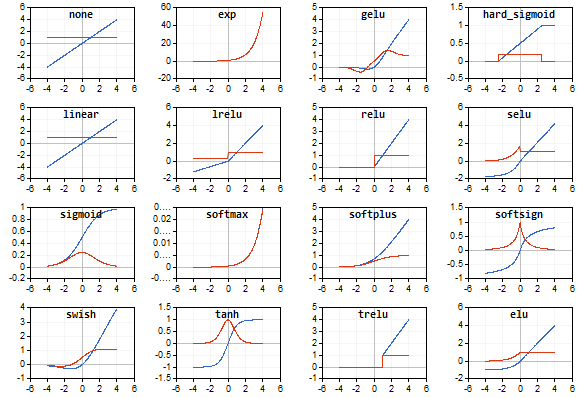

In [ ]:
# необходимые пакеты для tensorflow
# import matplotlib.pyplot as plt
# import seaborn

# import numpy as np
# import pandas as pd

# from tensorflow.keras.models import Model
# from tensorflow.keras.datasets import mnist, fashion_mnist, cifar10
# from tensorflow.keras.layers import (
#     Dense,
#     Flatten,
#     Input,
#     AveragePooling2D,
#     Conv2DTranspose,
#     Activation,
#     MaxPooling2D,
#     Conv2D,
#     BatchNormalization,
# )
# from tensorflow.keras import backend as K
# from tensorflow.keras.optimizers import Adam
# from tensorflow.keras import utils
# # from google.colab import files

# from tensorflow.keras.preprocessing import image
# import numpy as np

# from PIL import Image
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler

In [ ]:
# необходимые пакеты
import matplotlib.pyplot as plt
import seaborn

import numpy as np
import pandas as pd

from torch.nn import Module

from torch.nn import (
    Linear,
    Flatten,
    Conv2d,
    AvgPool2d,
    ConvTranspose2d,
    ReLU,Sigmoid,
    MaxPool2d,
    BatchNorm2d,
)
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

import torch
from torch import nn
from torch import optim

import numpy as np

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

**MNIST**

Строим данные для сверточной сети

In [ ]:
transfor_gray = torchvision.transforms.Compose([
        transforms.ToTensor(),

                                    ])

In [ ]:
# загрузка тренировочных и тестовых данных
train_dataset = torchvision.datasets.MNIST(root='data/',
                                             train=True,
                                             transform=transfor_gray,
                                             download=True)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset,
                                           batch_size=64,
                                           shuffle=True)
batch_size_test = 8
test_dataset = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transfor_gray)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size_test,
                                         shuffle=False)


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 496kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.26MB/s]


данные

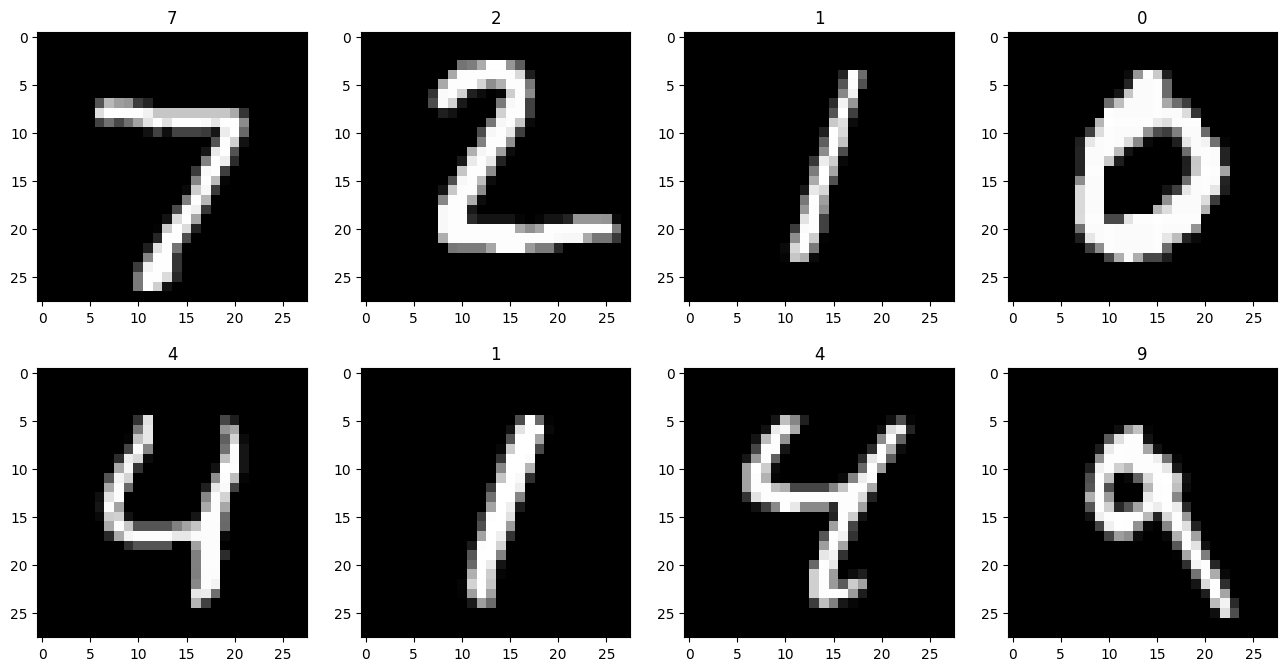

In [ ]:
for data in test_loader:
    break

n, k = 4, batch_size_test // 4 + 1 * int((batch_size_test % 4)>0)
images = data[0].cpu().numpy()
labels = data[1].cpu().numpy()
fig, ax = plt.subplots(k, n, figsize=(n*4, 4*k))
for ki in range(k):
    for ni in range(n):
        try:
            im = images[ni + ki*4, 0,  :,:]
            label = labels[ni + ki*4]
            ax[ki, ni].imshow(im)
            ax[ki, ni].set_title(str(label))
        except:
            pass


In [ ]:
device = "cuda" if  torch.cuda.is_available() else "cpu"

Нейросеть

Многослойный перцептрон со слоем softmax

In [ ]:
class Net(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 8 * hidden_dim)
        self.fc2 = nn.Linear(8 * hidden_dim, 4 * hidden_dim)
        self.fc3 = nn.Linear(4 * hidden_dim, 2 * hidden_dim)
        self.fc4 = nn.Linear(2 * hidden_dim, hidden_dim)
        self.fc5 = nn.Linear(hidden_dim, output_dim)


    def forward(self, x):
        x = x.view(x.shape[0], -1)
        x = self.fc1(x)
        x = F.leaky_relu(x)
        x = self.fc2(x)
        x = F.leaky_relu(x)
        x = self.fc3(x)
        x = F.leaky_relu(x)
        x = self.fc4(x)
        x = F.leaky_relu(x)
        x = self.fc5(x)
        return torch.nn.functional.softmax(x)

mlp = Net(input_dim=28*28,hidden_dim=1, output_dim=10).to(device)
print(mlp)

Net(
  (fc1): Linear(in_features=784, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=4, bias=True)
  (fc3): Linear(in_features=4, out_features=2, bias=True)
  (fc4): Linear(in_features=2, out_features=1, bias=True)
  (fc5): Linear(in_features=1, out_features=10, bias=True)
)


Сверточная нейросеть

In [ ]:
class NetC(nn.Module):

    def __init__(self, output_dim, input_dim=1):
        super(NetC, self).__init__()
        self.dp_one = nn.Dropout(0.2)
        self.dp_two = nn.Dropout(0.2)

        self.bn_one = torch.nn.BatchNorm2d(input_dim)
        self.conv_one = torch.nn.Conv2d(input_dim, 30, 3)#30
        self.bn_two = torch.nn.BatchNorm2d(30)
        self.conv_two = torch.nn.Conv2d(30, 60, 3)#
        self.bn_three = torch.nn.BatchNorm2d(60)
        self.conv_three = torch.nn.Conv2d(60, 120, 3)
        self.bn_four = torch.nn.BatchNorm2d(120)
        self.fc1 = torch.nn.Linear(120, 200)
        self.fc2 = torch.nn.Linear(200, 60)
        self.out = torch.nn.Linear(60, output_dim)

    def forward(self, x):
        x = self.bn_one(x)# 28x28x3
        x = self.conv_one(x)#26x26x30
        x = F.relu(x)
        x = F.max_pool2d(x, 2)#30x13x13

        x = self.bn_two(x)
        x = self.conv_two(x)#60 x 11x11
        x = F.relu(x)
        x = F.max_pool2d(x, 2)#60 x 5 x 5

        x = self.bn_three(x)
        x = self.conv_three(x)#120 x 3 x 3
        x = F.leaky_relu(x, 0.1)
        x = F.max_pool2d(x, 2) #120 x 1 x 1

        x = self.bn_four(x)
        x = x.view(x.size(0), -1) # 120 x 1
        x = self.dp_one(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dp_two(x)
        x = self.fc2(x)
        x = F.relu(x)
        return self.out(x)

net = NetC(output_dim=10).to(device)
print(net)

NetC(
  (dp_one): Dropout(p=0.2, inplace=False)
  (dp_two): Dropout(p=0.2, inplace=False)
  (bn_one): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_one): Conv2d(1, 30, kernel_size=(3, 3), stride=(1, 1))
  (bn_two): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_two): Conv2d(30, 60, kernel_size=(3, 3), stride=(1, 1))
  (bn_three): BatchNorm2d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_three): Conv2d(60, 120, kernel_size=(3, 3), stride=(1, 1))
  (bn_four): BatchNorm2d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=120, out_features=200, bias=True)
  (fc2): Linear(in_features=200, out_features=60, bias=True)
  (out): Linear(in_features=60, out_features=10, bias=True)
)


Оптимизатор

In [ ]:
# for convoution net
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
# for MLP
optimizer_mlp = torch.optim.Adam(mlp.parameters(), lr=0.01)

criterion = nn.CrossEntropyLoss()

In [ ]:
num_epochs = 5
mlp.train()

for epoch in range(num_epochs):
    running_loss, running_items, running_right = 0.0, 0.0, 0.0
    for i, data in enumerate(train_loader):
        inputs, labels = data[0].to(device), data[1].to(device)

        # обнуляем градиент
        optimizer_mlp.zero_grad()

        outputs = mlp(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_mlp.step()

        # выводим статистику о процессе обучения
        running_loss += loss.item()
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum()

        # выводим статистику о процессе обучения
        if i % 300 == 0:    # печатаем каждые 300 mini-batches
            mlp.eval()

            print(f'Epoch [{epoch + 1}/{num_epochs}]. ' \
                  f'Step [{i + 1}/{len(train_loader)}]. ' \
                  f'Loss: {running_loss / running_items:.3f}. ' \
                  f'Acc: {running_right / running_items:.3f}', end='. ')
            running_loss, running_items, running_right = 0.0, 0.0, 0.0

            test_running_right, test_running_total = 0.0, 0.0
            for i, data in enumerate(test_loader):

                test_outputs = mlp(data[0].to(device))
                test_running_total += len(data[1])
                test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum()

            print(f'Test acc: {test_running_right / test_running_total:.3f}')

        mlp.train()

print('Training is finished!')

/tmp/ipykernel_3566/2156362954.py:22: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return torch.nn.functional.softmax(x)


Epoch [1/5]. Step [1/938]. Loss: 0.036. Acc: 0.094. Test acc: 0.113
Epoch [1/5]. Step [301/938]. Loss: 0.034. Acc: 0.319. Test acc: 0.468
Epoch [1/5]. Step [601/938]. Loss: 0.031. Acc: 0.520. Test acc: 0.528
Epoch [1/5]. Step [901/938]. Loss: 0.030. Acc: 0.543. Test acc: 0.551
Epoch [2/5]. Step [1/938]. Loss: 0.030. Acc: 0.578. Test acc: 0.558
Epoch [2/5]. Step [301/938]. Loss: 0.030. Acc: 0.555. Test acc: 0.562
Epoch [2/5]. Step [601/938]. Loss: 0.030. Acc: 0.565. Test acc: 0.555
Epoch [2/5]. Step [901/938]. Loss: 0.030. Acc: 0.553. Test acc: 0.528
Epoch [3/5]. Step [1/938]. Loss: 0.031. Acc: 0.500. Test acc: 0.550
Epoch [3/5]. Step [301/938]. Loss: 0.030. Acc: 0.561. Test acc: 0.566
Epoch [3/5]. Step [601/938]. Loss: 0.030. Acc: 0.555. Test acc: 0.564
Epoch [3/5]. Step [901/938]. Loss: 0.030. Acc: 0.569. Test acc: 0.571
Epoch [4/5]. Step [1/938]. Loss: 0.030. Acc: 0.547. Test acc: 0.559
Epoch [4/5]. Step [301/938]. Loss: 0.030. Acc: 0.557. Test acc: 0.571
Epoch [4/5]. Step [601/938].

In [ ]:
inputs.shape

torch.Size([32, 1, 28, 28])

In [ ]:
num_epochs = 5
net.train()

for epoch in range(num_epochs):
    running_loss, running_items, running_right = 0.0, 0.0, 0.0
    for i, data in enumerate(train_loader):
        inputs, labels = data[0].to(device), data[1].to(device)

        # обнуляем градиент
        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # выводим статистику о процессе обучения
        running_loss += loss.item()
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum()

        # выводим статистику о процессе обучения
        if i % 300 == 0:    # печатаем каждые 300 mini-batches
            net.eval()

            print(f'Epoch [{epoch + 1}/{num_epochs}]. ' \
                  f'Step [{i + 1}/{len(train_loader)}]. ' \
                  f'Loss: {running_loss / running_items:.3f}. ' \
                  f'Acc: {running_right / running_items:.3f}', end='. ')
            running_loss, running_items, running_right = 0.0, 0.0, 0.0

            test_running_right, test_running_total = 0.0, 0.0
            for i, data in enumerate(test_loader):

                test_outputs = net(data[0].to(device))
                test_running_total += len(data[1])
                test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum()

            print(f'Test acc: {test_running_right / test_running_total:.3f}')

        mlp.train()

print('Training is finished!')

Epoch [1/5]. Step [1/938]. Loss: 0.036. Acc: 0.156. Test acc: 0.103
Epoch [1/5]. Step [301/938]. Loss: 0.006. Acc: 0.886. Test acc: 0.966
Epoch [1/5]. Step [601/938]. Loss: 0.002. Acc: 0.958. Test acc: 0.970
Epoch [1/5]. Step [901/938]. Loss: 0.002. Acc: 0.967. Test acc: 0.964
Epoch [2/5]. Step [1/938]. Loss: 0.001. Acc: 0.984. Test acc: 0.965
Epoch [2/5]. Step [301/938]. Loss: 0.002. Acc: 0.970. Test acc: 0.960
Epoch [2/5]. Step [601/938]. Loss: 0.002. Acc: 0.972. Test acc: 0.948
Epoch [2/5]. Step [901/938]. Loss: 0.002. Acc: 0.969. Test acc: 0.975
Epoch [3/5]. Step [1/938]. Loss: 0.003. Acc: 0.969. Test acc: 0.979
Epoch [3/5]. Step [301/938]. Loss: 0.001. Acc: 0.976. Test acc: 0.977
Epoch [3/5]. Step [601/938]. Loss: 0.002. Acc: 0.974. Test acc: 0.977
Epoch [3/5]. Step [901/938]. Loss: 0.002. Acc: 0.975. Test acc: 0.976
Epoch [4/5]. Step [1/938]. Loss: 0.001. Acc: 0.984. Test acc: 0.976
Epoch [4/5]. Step [301/938]. Loss: 0.001. Acc: 0.982. Test acc: 0.980
Epoch [4/5]. Step [601/938].

Посмотреть на внутренние слои через дополнительные модели:

- x1 - 1я нормализация
- x2 - 1-я свертка
- x3 - 2-я нормализация
- x4 - 1-й пулинг
- x5 - 3-я свертка

In [ ]:
class NetC(nn.Module):

    def __init__(self, output_dim, input_dim=1):
        super(NetC, self).__init__()
        self.dp_one = nn.Dropout(0.2)
        self.dp_two = nn.Dropout(0.2)

        self.bn_one = torch.nn.BatchNorm2d(input_dim)
        self.conv_one = torch.nn.Conv2d(input_dim, 30, 3)#30
        self.bn_two = torch.nn.BatchNorm2d(30)
        self.conv_two = torch.nn.Conv2d(30, 60, 3)#
        self.bn_three = torch.nn.BatchNorm2d(60)
        self.conv_three = torch.nn.Conv2d(60, 120, 3)
        self.bn_four = torch.nn.BatchNorm2d(120)
        self.fc1 = torch.nn.Linear(120, 200)
        self.fc2 = torch.nn.Linear(200, 60)
        self.out = torch.nn.Linear(60, output_dim)

    def forward(self, x):
        x1 = self.bn_one(x)# 28x28x3
        x = x1
        x = self.conv_one(x)#26x26x30
        x = F.relu(x)
        x2 = x
        x = F.max_pool2d(x, 2)#30x13x13
        x4 = x

        x = self.bn_two(x)
        x3 = x
        x = self.conv_two(x)#60 x 11x11
        x = F.relu(x)
        x = F.max_pool2d(x, 2)#60 x 5 x 5

        x = self.bn_three(x)
        x = self.conv_three(x)#120 x 3 x 3
        x = F.leaky_relu(x, 0.1)
        x5 = x
        x = F.max_pool2d(x, 2) #120 x 1 x 1

        x = self.bn_four(x)
        x = x.view(x.size(0), -1) # 120 x 1
        x = self.dp_one(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dp_two(x)
        x = self.fc2(x)
        x = F.relu(x)
        return self.out(x), x1, x2, x3, x4, x5

net = NetC(output_dim=10).to(device)
print(net)
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)

NetC(
  (dp_one): Dropout(p=0.2, inplace=False)
  (dp_two): Dropout(p=0.2, inplace=False)
  (bn_one): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_one): Conv2d(1, 30, kernel_size=(3, 3), stride=(1, 1))
  (bn_two): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_two): Conv2d(30, 60, kernel_size=(3, 3), stride=(1, 1))
  (bn_three): BatchNorm2d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_three): Conv2d(60, 120, kernel_size=(3, 3), stride=(1, 1))
  (bn_four): BatchNorm2d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=120, out_features=200, bias=True)
  (fc2): Linear(in_features=200, out_features=60, bias=True)
  (out): Linear(in_features=60, out_features=10, bias=True)
)


In [ ]:
num_epochs = 5
net.train()

for epoch in range(num_epochs):
    running_loss, running_items, running_right = 0.0, 0.0, 0.0
    for i, data in enumerate(train_loader):
        inputs, labels = data[0].to(device), data[1].to(device)

        # обнуляем градиент
        optimizer.zero_grad()

        outputs, _,_,_,_,_ = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # выводим статистику о процессе обучения
        running_loss += loss.item()
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum()

        # выводим статистику о процессе обучения
        if i % 300 == 0:    # печатаем каждые 300 mini-batches
            net.eval()

            print(f'Epoch [{epoch + 1}/{num_epochs}]. ' \
                  f'Step [{i + 1}/{len(train_loader)}]. ' \
                  f'Loss: {running_loss / running_items:.3f}. ' \
                  f'Acc: {running_right / running_items:.3f}', end='. ')
            running_loss, running_items, running_right = 0.0, 0.0, 0.0

            test_running_right, test_running_total = 0.0, 0.0
            for i, data in enumerate(test_loader):

                test_outputs, x1,x2,x3,x4,x5 = net(data[0].to(device))
                test_running_total += len(data[1])
                test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum()

            print(f'Test acc: {test_running_right / test_running_total:.3f}')

        mlp.train()

print('Training is finished!')

Epoch [1/5]. Step [1/938]. Loss: 0.036. Acc: 0.078. Test acc: 0.103
Epoch [1/5]. Step [301/938]. Loss: 0.006. Acc: 0.892. Test acc: 0.971
Epoch [1/5]. Step [601/938]. Loss: 0.003. Acc: 0.955. Test acc: 0.963
Epoch [1/5]. Step [901/938]. Loss: 0.002. Acc: 0.965. Test acc: 0.960
Epoch [2/5]. Step [1/938]. Loss: 0.001. Acc: 0.969. Test acc: 0.971
Epoch [2/5]. Step [301/938]. Loss: 0.002. Acc: 0.966. Test acc: 0.976
Epoch [2/5]. Step [601/938]. Loss: 0.002. Acc: 0.972. Test acc: 0.980
Epoch [2/5]. Step [901/938]. Loss: 0.002. Acc: 0.976. Test acc: 0.979
Epoch [3/5]. Step [1/938]. Loss: 0.001. Acc: 0.984. Test acc: 0.975
Epoch [3/5]. Step [301/938]. Loss: 0.001. Acc: 0.976. Test acc: 0.978
Epoch [3/5]. Step [601/938]. Loss: 0.002. Acc: 0.975. Test acc: 0.971
Epoch [3/5]. Step [901/938]. Loss: 0.002. Acc: 0.976. Test acc: 0.976
Epoch [4/5]. Step [1/938]. Loss: 0.000. Acc: 1.000. Test acc: 0.981
Epoch [4/5]. Step [301/938]. Loss: 0.001. Acc: 0.979. Test acc: 0.978
Epoch [4/5]. Step [601/938].

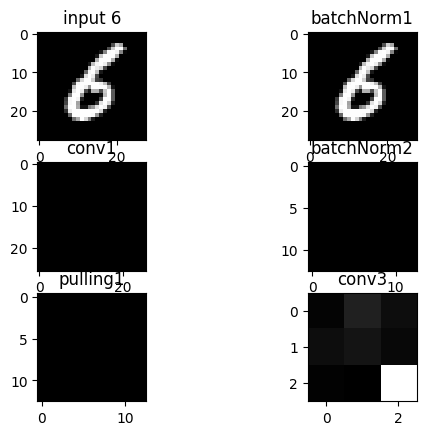

In [ ]:
test_outputs, x1,x2,x3,x4,x5 = net(data[0].to(device))
label =  data[1]
m0 =  2

g1 = x1[m0, 0, :, :].cpu().detach().numpy()
plt.subplot(322)
plt.imshow(g1)
plt.title("batchNorm1")

g1 = data[0][m0, 0, :, :].cpu().detach().numpy()
plt.subplot(321)
plt.imshow(g1)
plt.title("input " + str(label[m0].item()))
g1 =  x2[m0, 0, :, :].cpu().detach().numpy()

plt.subplot(323)
plt.imshow(g1)
plt.title("conv1")

g1 =  x3[m0, 0, :, :].cpu().detach().numpy()
plt.subplot(324)
plt.title("batchNorm2")
plt.imshow(g1)

g1 =  x4[m0, 0, :, :].cpu().detach().numpy()
plt.subplot(325)
plt.imshow(g1)
plt.title("pulling1")

g1 =  x5[m0, 0, :, :].cpu().detach().numpy()
plt.subplot(326)
plt.imshow(g1)
plt.title("conv3")
plt.show()

In [ ]:
transfor_rgb = torchvision.transforms.Compose([transforms.Resize(28),
                                       transforms.ToTensor(),
                                       transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                                            std=[0.229, 0.224, 0.225])])
train_dataset = torchvision.datasets.CIFAR10(root='data/',
                                             train=True,
                                             transform=transfor_rgb,
                                             download=True)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset,
                                           batch_size=64,
                                           shuffle=True)

batch_size_test = 8
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transfor_rgb)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size_test,
                                         shuffle=False)

 50%|████▉     | 85.1M/170M [11:42<11:45, 121kB/s]


KeyboardInterrupt: 

## Задание 1.

1.1 адаптировать модель к набору данных CIFAR10

1.2 провести обучение - получить результаты (разбить на студентов на группы и создать разные сетки - средний пуллинг, максимальный , стек сверток, включать нормализацию, включать дропаут)

1.3  собрать результаты - сравнить

## Исследование по варианту

Выполните один вариант в соответствии с номером в списке группы.

**Вариант 1. MaxPooling или AvgPooling.** На одной архитектуре сравните максимальный и средний pooling с одинаковыми размером окна 2×2 и шагом 2 во всех трёх блоках. Обучите обе модели заново. Сравните валидационную accuracy и покажите карты после первого pooling для одного и того же изображения. Объясните, какие особенности откликов сохраняет каждый способ агрегации.

**Вариант 2. BatchNorm.** Сравните одну архитектуру с BatchNorm и без неё, заменив все слои BatchNorm на `nn.Identity`. Остальные настройки сохраните. Покажите кривые train/val loss и валидационную accuracy. Для loss усредняйте потери по объектам, учитывая размер каждого батча. Объясните наблюдаемые различия и роль режимов `train()` / `eval()`.

**Вариант 3. Dropout.** Сравните вероятности dropout 0, 0.2 и 0.5, задавая одинаковое значение обоим Dropout-слоям перед полносвязными слоями. Сравните train и validation accuracy, измеренные в режиме `eval()`, и разрыв между ними. Объясните, есть ли в ваших результатах признаки переобучения или недостаточного обучения.



In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from IPython.display import display

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device =", device)

EPOCHS = 5
BATCH_SIZE = 128
NUM_WORKERS = 2
MAX_TRAIN_SAMPLES = None

device = cuda


In [ ]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

train_dataset_full = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform_test
)

if MAX_TRAIN_SAMPLES is not None:
    g = torch.Generator().manual_seed(42)
    idx = torch.randperm(len(train_dataset_full), generator=g)[:MAX_TRAIN_SAMPLES].tolist()
    train_dataset = Subset(train_dataset_full, idx)
else:
    train_dataset = train_dataset_full

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)
train_eval_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

classes = train_dataset_full.classes
print("train size:", len(train_dataset), "test size:", len(test_dataset))
print("classes:", classes)

xb, yb = next(iter(train_loader))
print("batch shape:", xb.shape, "labels shape:", yb.shape)

100%|██████████| 170M/170M [26:14<00:00, 108kB/s] 


train size: 50000 test size: 10000
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
batch shape: torch.Size([128, 3, 32, 32]) labels shape: torch.Size([128])


In [ ]:
class CIFARCNN(nn.Module):
    def __init__(self, num_classes=10, pool_type="max", use_bn=True,
                 dropout_p=0.2, stack_conv=False):
        super().__init__()
        assert pool_type in ("max", "avg")

        def make_block(in_c, out_c, num_convs):
            layers = []
            c = in_c
            for _ in range(num_convs):
                layers.append(
                    nn.Conv2d(c, out_c, kernel_size=3, padding=1, bias=not use_bn)
                )
                if use_bn:
                    layers.append(nn.BatchNorm2d(out_c))
                layers.append(nn.ReLU(inplace=True))
                c = out_c
            return nn.Sequential(*layers)

        n_conv = 2 if stack_conv else 1

        self.block1 = make_block(3, 32, n_conv)
        self.block2 = make_block(32, 64, n_conv)
        self.block3 = make_block(64, 128, n_conv)

        self.pool = nn.MaxPool2d(2) if pool_type == "max" else nn.AvgPool2d(2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.dropout1 = nn.Dropout(dropout_p)
        self.dropout2 = nn.Dropout(dropout_p)

        self.fc1 = nn.Linear(128, 100)
        self.fc2 = nn.Linear(100, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.pool(x)

        x = self.block2(x)
        x = self.pool(x)

        x = self.block3(x)
        x = self.pool(x)

        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)

        x = self.dropout1(x)
        x = F.relu(self.fc1(x))
        x = self.dropout2(x)
        x = self.fc2(x)
        return x

tmp_model = CIFARCNN().to(device)
tmp_x = torch.randn(4, 3, 32, 32).to(device)
print("output shape:", tmp_model(tmp_x).shape)

output shape: torch.Size([4, 10])


In [ ]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    total = 0
    correct = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total += x.size(0)
        correct += (logits.argmax(1) == y).sum().item()

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total = 0
    correct = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        total += x.size(0)
        correct += (logits.argmax(1) == y).sum().item()

    return total_loss / total, correct / total


def train_model(config, epochs=EPOCHS, lr=1e-3, seed=42):
    set_seed(seed)
    model = CIFARCNN(**config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "epoch": [],
        "train_loss_epoch": [],
        "train_acc_epoch": [],
        "train_loss_eval": [],
        "train_acc_eval": [],
        "val_loss": [],
        "val_acc": [],
    }

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        tr_loss_eval, tr_acc_eval = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, test_loader)

        history["epoch"].append(epoch)
        history["train_loss_epoch"].append(tr_loss)
        history["train_acc_epoch"].append(tr_acc)
        history["train_loss_eval"].append(tr_loss_eval)
        history["train_acc_eval"].append(tr_acc_eval)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"epoch {epoch:02d}/{epochs} | "
            f"train_loss={tr_loss:.4f}, train_acc={tr_acc:.4f} | "
            f"train_eval_acc={tr_acc_eval:.4f} | "
            f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}"
        )

    return model, history


Модель: MaxPool + BN + Dropout0.2
epoch 01/5 | train_loss=1.5146, train_acc=0.4393 | train_eval_acc=0.4818 | val_loss=1.4850, val_acc=0.4762
epoch 02/5 | train_loss=1.2236, train_acc=0.5587 | train_eval_acc=0.5921 | val_loss=1.1443, val_acc=0.5779
epoch 03/5 | train_loss=1.1153, train_acc=0.5988 | train_eval_acc=0.6166 | val_loss=1.0812, val_acc=0.6014
epoch 04/5 | train_loss=1.0440, train_acc=0.6259 | train_eval_acc=0.6105 | val_loss=1.1633, val_acc=0.5907
epoch 05/5 | train_loss=0.9888, train_acc=0.6475 | train_eval_acc=0.6911 | val_loss=0.9287, val_acc=0.6733

Модель: AvgPool + BN + Dropout0.2
epoch 01/5 | train_loss=1.5789, train_acc=0.4089 | train_eval_acc=0.4753 | val_loss=1.4754, val_acc=0.4660
epoch 02/5 | train_loss=1.2705, train_acc=0.5365 | train_eval_acc=0.5593 | val_loss=1.2094, val_acc=0.5511
epoch 03/5 | train_loss=1.1473, train_acc=0.5841 | train_eval_acc=0.6010 | val_loss=1.1313, val_acc=0.5835
epoch 04/5 | train_loss=1.0768, train_acc=0.6142 | train_eval_acc=0.6056 |

,model,train_acc_eval,val_acc,gap_train_val,val_loss
2,StackConv + MaxPool + BN + Dropout0.2,0.83654,0.7919,0.04464,0.604702
4,MaxPool + BN + Dropout0.0,0.71590,0.6831,0.03280,0.910299
0,MaxPool + BN + Dropout0.2,0.69106,0.6733,0.01776,0.928676
1,AvgPool + BN + Dropout0.2,0.65684,0.6469,0.00994,0.991481
3,MaxPool + NoBN + Dropout0.2,0.62750,0.6127,0.01480,1.064926


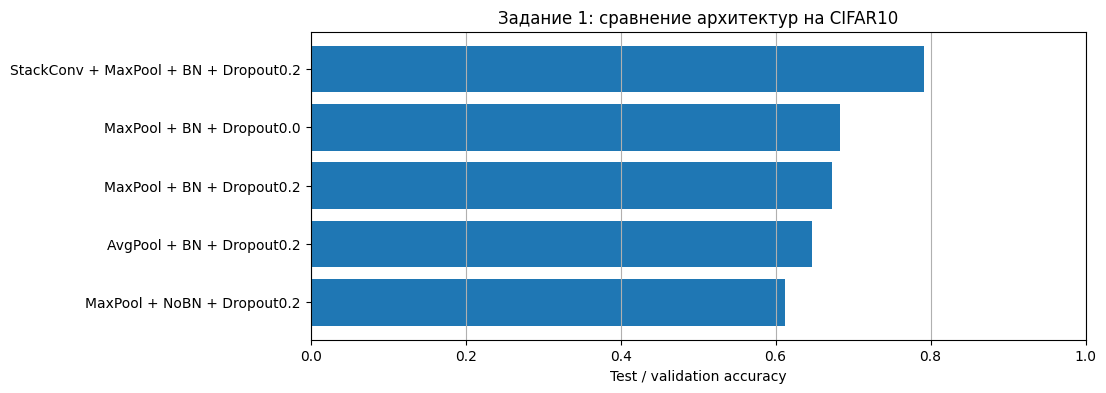

In [ ]:
configs = [
    {
        "name": "MaxPool + BN + Dropout0.2",
        "kwargs": dict(pool_type="max", use_bn=True, dropout_p=0.2, stack_conv=False),
    },
    {
        "name": "AvgPool + BN + Dropout0.2",
        "kwargs": dict(pool_type="avg", use_bn=True, dropout_p=0.2, stack_conv=False),
    },
    {
        "name": "StackConv + MaxPool + BN + Dropout0.2",
        "kwargs": dict(pool_type="max", use_bn=True, dropout_p=0.2, stack_conv=True),
    },
    {
        "name": "MaxPool + NoBN + Dropout0.2",
        "kwargs": dict(pool_type="max", use_bn=False, dropout_p=0.2, stack_conv=False),
    },
    {
        "name": "MaxPool + BN + Dropout0.0",
        "kwargs": dict(pool_type="max", use_bn=True, dropout_p=0.0, stack_conv=False),
    },
]

task1_results = []
task1_histories = {}
task1_models = {}

for cfg in configs:
    print("\n" + "=" * 80)
    print("Модель:", cfg["name"])
    print("=" * 80)

    model, hist = train_model(cfg["kwargs"], epochs=EPOCHS)

    task1_models[cfg["name"]] = model
    task1_histories[cfg["name"]] = hist

    task1_results.append({
        "model": cfg["name"],
        "train_acc_eval": hist["train_acc_eval"][-1],
        "val_acc": hist["val_acc"][-1],
        "gap_train_val": hist["train_acc_eval"][-1] - hist["val_acc"][-1],
        "val_loss": hist["val_loss"][-1],
    })

task1_df = pd.DataFrame(task1_results).sort_values("val_acc", ascending=False)
display(task1_df)

plt.figure(figsize=(10, 4))
plt.barh(task1_df["model"], task1_df["val_acc"])
plt.xlim(0, 1)
plt.xlabel("Test / validation accuracy")
plt.title("Задание 1: сравнение архитектур на CIFAR10")
plt.gca().invert_yaxis()
plt.grid(True, axis="x")
plt.show()

Лучшей конфигурацией оказался StackConv + MaxPool + BN + Dropout0.2, и главный вклад даёт именно стек из двух свёрток 3×3 в каждом блоке, затем BatchNorm, тогда как замена MaxPool на AvgPool даёт лишь небольшой проигрыш, а Dropout 0.2 при 5 эпохах даже слегка вредит, поскольку модель ещё не переобучена, регулировать нечего.

In [ ]:
dropout_ps = [0.0, 0.2, 0.5]

dropout_results = []
dropout_histories = {}
dropout_models = {}

for p in dropout_ps:
    print("\n" + "=" * 80)
    print(f"Dropout p = {p}")
    print("=" * 80)

    cfg = dict(pool_type="max", use_bn=True, dropout_p=p, stack_conv=False)
    model, hist = train_model(cfg, epochs=EPOCHS)

    key = f"dropout={p}"
    dropout_models[key] = model
    dropout_histories[key] = hist

    train_acc_eval = hist["train_acc_eval"][-1]
    val_acc = hist["val_acc"][-1]
    gap = train_acc_eval - val_acc

    dropout_results.append({
        "dropout_p": p,
        "train_acc_eval": train_acc_eval,
        "val_acc": val_acc,
        "gap_train_minus_val": gap,
        "val_loss": hist["val_loss"][-1],
    })

dropout_df = pd.DataFrame(dropout_results)
display(dropout_df)


Dropout p = 0.0
epoch 01/5 | train_loss=1.4114, train_acc=0.4839 | train_eval_acc=0.4878 | val_loss=1.4745, val_acc=0.4811
epoch 02/5 | train_loss=1.0712, train_acc=0.6163 | train_eval_acc=0.5937 | val_loss=1.1610, val_acc=0.5757
epoch 03/5 | train_loss=0.9375, train_acc=0.6678 | train_eval_acc=0.5974 | val_loss=1.1990, val_acc=0.5797
epoch 04/5 | train_loss=0.8539, train_acc=0.6974 | train_eval_acc=0.6267 | val_loss=1.1433, val_acc=0.6004
epoch 05/5 | train_loss=0.7912, train_acc=0.7232 | train_eval_acc=0.7159 | val_loss=0.9103, val_acc=0.6831

Dropout p = 0.2
epoch 01/5 | train_loss=1.5146, train_acc=0.4393 | train_eval_acc=0.4818 | val_loss=1.4850, val_acc=0.4762
epoch 02/5 | train_loss=1.2236, train_acc=0.5587 | train_eval_acc=0.5921 | val_loss=1.1443, val_acc=0.5779
epoch 03/5 | train_loss=1.1153, train_acc=0.5988 | train_eval_acc=0.6166 | val_loss=1.0812, val_acc=0.6014
epoch 04/5 | train_loss=1.0440, train_acc=0.6259 | train_eval_acc=0.6105 | val_loss=1.1633, val_acc=0.5907
epo

,dropout_p,train_acc_eval,val_acc,gap_train_minus_val,val_loss
0,0.0,0.71590,0.6831,0.03280,0.910299
1,0.2,0.69106,0.6733,0.01776,0.928676
2,0.5,0.60102,0.5869,0.01412,1.130753


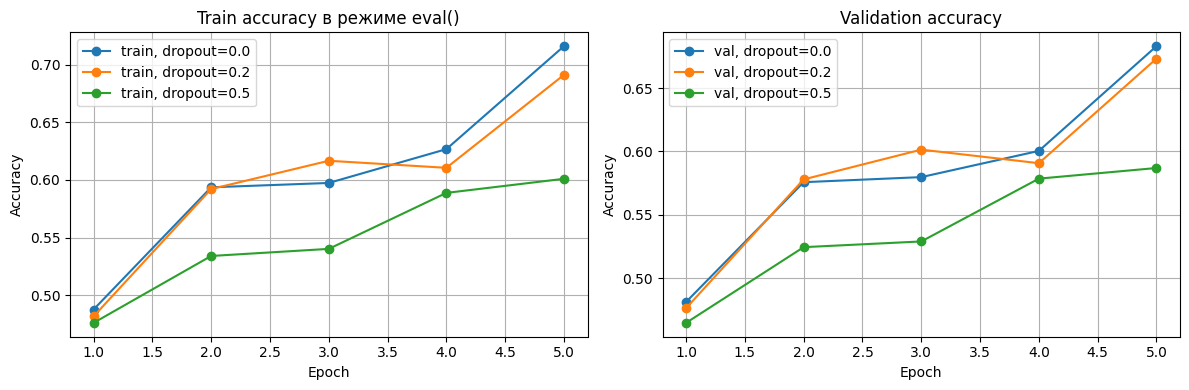

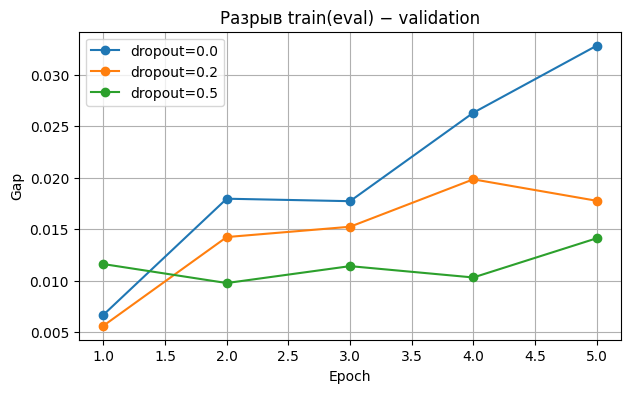

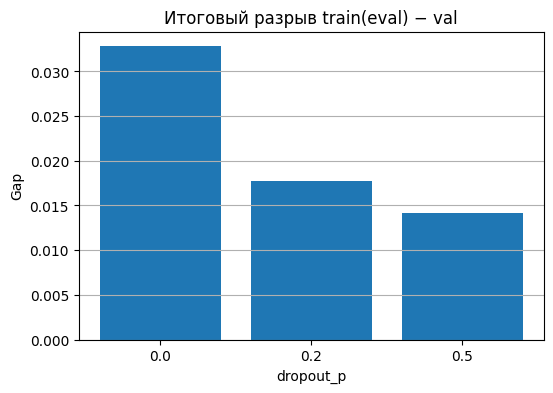

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for key, hist in dropout_histories.items():
    plt.plot(hist["epoch"], hist["train_acc_eval"], marker="o", label=f"train, {key}")
plt.title("Train accuracy в режиме eval()")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
for key, hist in dropout_histories.items():
    plt.plot(hist["epoch"], hist["val_acc"], marker="o", label=f"val, {key}")
plt.title("Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
for key, hist in dropout_histories.items():
    gaps = [tr - va for tr, va in zip(hist["train_acc_eval"], hist["val_acc"])]
    plt.plot(hist["epoch"], gaps, marker="o", label=key)

plt.title("Разрыв train(eval) − validation")
plt.xlabel("Epoch")
plt.ylabel("Gap")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar([str(p) for p in dropout_df["dropout_p"]], dropout_df["gap_train_minus_val"])
plt.title("Итоговый разрыв train(eval) − val")
plt.xlabel("dropout_p")
plt.ylabel("Gap")
plt.grid(True, axis="y")
plt.show()

In [ ]:
final_dropout_table = dropout_df.copy()
final_dropout_table["train_acc_eval"] = final_dropout_table["train_acc_eval"].round(4)
final_dropout_table["val_acc"] = final_dropout_table["val_acc"].round(4)
final_dropout_table["gap_train_minus_val"] = final_dropout_table["gap_train_minus_val"].round(4)
final_dropout_table["val_loss"] = final_dropout_table["val_loss"].round(4)

display(final_dropout_table.sort_values("dropout_p"))

,dropout_p,train_acc_eval,val_acc,gap_train_minus_val,val_loss
0,0.0,0.7159,0.6831,0.0328,0.9103
1,0.2,0.6911,0.6733,0.0178,0.9287
2,0.5,0.6010,0.5869,0.0141,1.1308


При p = 0, 0.2 и 0.5 train и val accuracy в режиме eval() падает, а также разрыв train − val монотонно падает: 0.0328 - 0.0178 - 0.0141, то есть dropout действительно работает как регуляризатор и уменьшает переобучение. Однако абсолютная val accuracy при этом снижается, а val_loss растёт, что говорит о том, что признаков переобучения в эксперименте нет, а при p = 0.5 появляются признаки недообучения — половина нейронов отключена, эффективная ёмкость падает, и за 5 эпох модель просто не успевает выучить признаки. Таким образом, в данных условиях dropout уменьшает разрыв, но не улучшает обобщение, потому что регулировать пока нечего, а сильная регуляризация обходится слишком дорого.

## Задание 2

2.1 добавить резидуальный обход

2.2 сделать более глубокую сеть

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_c)

        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_c),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return F.relu(out)

In [ ]:
class DeepCNN(nn.Module):
    def __init__(self, num_classes=10, residual=True, dropout_p=0.2):
        super().__init__()

        def block(in_c, out_c, stride=1):
            if residual:
                return ResidualBlock(in_c, out_c, stride=stride)
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, stride=stride, padding=1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, 3, stride=1, padding=1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
            )

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )

        self.stage1 = nn.Sequential(block(32, 32), block(32, 32))
        self.stage2 = nn.Sequential(block(32, 64, stride=2), block(64, 64))
        self.stage3 = nn.Sequential(block(64, 128, stride=2), block(128, 128))

        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout1 = nn.Dropout(dropout_p)
        self.dropout2 = nn.Dropout(dropout_p)
        self.fc1 = nn.Linear(128, 100)
        self.fc2 = nn.Linear(100, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout1(x)
        x = F.relu(self.fc1(x))
        x = self.dropout2(x)
        return self.fc2(x)


for tag, res in [("DeepCNN (no residual)", False), ("DeepResNet (residual)", True)]:
    m = DeepCNN(residual=res).to(device)
    out = m(torch.randn(4, 3, 32, 32).to(device))
    n_params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{tag}: out={tuple(out.shape)}, params={n_params:,}")

baseline_params = sum(p.numel() for p in CIFARCNN(
    pool_type="max", use_bn=True, dropout_p=0.2, stack_conv=True
).parameters() if p.requires_grad)
print(f"CIFARCNN baseline (stack conv): params={baseline_params:,}")

DeepCNN (no residual): out=(4, 10), params=698,614
DeepResNet (residual): out=(4, 10), params=709,238
CIFARCNN baseline (stack conv): params=301,366


In [ ]:
def train_model_obj(model, name="model", epochs=EPOCHS, lr=1e-3, seed=42):
    set_seed(seed)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "epoch": [], "train_loss_epoch": [], "train_acc_epoch": [],
        "train_loss_eval": [], "train_acc_eval": [],
        "val_loss": [], "val_acc": [],
    }

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        tr_loss_eval, tr_acc_eval = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, test_loader)

        history["epoch"].append(epoch)
        history["train_loss_epoch"].append(tr_loss)
        history["train_acc_epoch"].append(tr_acc)
        history["train_loss_eval"].append(tr_loss_eval)
        history["train_acc_eval"].append(tr_acc_eval)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"[{name}] epoch {epoch:02d}/{epochs} | "
              f"train_loss={tr_loss:.4f}, train_acc={tr_acc:.4f} | "
              f"train_eval_acc={tr_acc_eval:.4f} | "
              f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")

    return model, history

In [ ]:
set_seed(42)
baseline_model = CIFARCNN(
    pool_type="max", use_bn=True, dropout_p=0.2, stack_conv=True
).to(device)
baseline_opt = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

baseline_hist = {"epoch": [], "train_acc_eval": [], "val_acc": [],
                 "val_loss": [], "train_loss_eval": []}
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(baseline_model, train_loader, baseline_opt)
    tr_le, tr_ae = evaluate(baseline_model, train_eval_loader)
    va_le, va_ae = evaluate(baseline_model, test_loader)
    baseline_hist["epoch"].append(epoch)
    baseline_hist["train_loss_eval"].append(tr_le)
    baseline_hist["train_acc_eval"].append(tr_ae)
    baseline_hist["val_loss"].append(va_le)
    baseline_hist["val_acc"].append(va_ae)
    print(f"[baseline] epoch {epoch:02d}/{EPOCHS} | "
          f"train_eval_acc={tr_ae:.4f} | val_loss={va_le:.4f}, val_acc={va_ae:.4f}")


deep_no_res_model = DeepCNN(residual=False, dropout_p=0.2)
deep_no_res_model, deep_no_res_hist = train_model_obj(
    deep_no_res_model, name="deep_no_residual", epochs=EPOCHS, seed=42
)

deep_res_model = DeepCNN(residual=True, dropout_p=0.2)
deep_res_model, deep_res_hist = train_model_obj(
    deep_res_model, name="deep_residual", epochs=EPOCHS, seed=42
)

[baseline] epoch 01/5 | train_eval_acc=0.6248 | val_loss=1.0807, val_acc=0.6088
[baseline] epoch 02/5 | train_eval_acc=0.6645 | val_loss=0.9952, val_acc=0.6508
[baseline] epoch 03/5 | train_eval_acc=0.7510 | val_loss=0.7886, val_acc=0.7229
[baseline] epoch 04/5 | train_eval_acc=0.7936 | val_loss=0.6949, val_acc=0.7610
[baseline] epoch 05/5 | train_eval_acc=0.8365 | val_loss=0.6047, val_acc=0.7919
[deep_no_residual] epoch 01/5 | train_loss=1.5416, train_acc=0.4138 | train_eval_acc=0.4865 | val_loss=1.4038, val_acc=0.4819
[deep_no_residual] epoch 02/5 | train_loss=1.0840, train_acc=0.6073 | train_eval_acc=0.5863 | val_loss=1.2673, val_acc=0.5770
[deep_no_residual] epoch 03/5 | train_loss=0.8624, train_acc=0.6942 | train_eval_acc=0.7016 | val_loss=0.8919, val_acc=0.6840
[deep_no_residual] epoch 04/5 | train_loss=0.7220, train_acc=0.7479 | train_eval_acc=0.7419 | val_loss=0.8294, val_acc=0.7140
[deep_no_residual] epoch 05/5 | train_loss=0.6231, train_acc=0.7854 | train_eval_acc=0.7754 | va

,model,params,train(eval),val_acc,val_loss,gap
0,baseline (задание 1),301366,0.8365,0.7919,0.6047,0.0446
2,deep + residual (2.1 + 2.2),709238,0.7961,0.7544,0.7148,0.0417
1,"deep, no residual (2.2)",698614,0.7754,0.7435,0.7870,0.0319


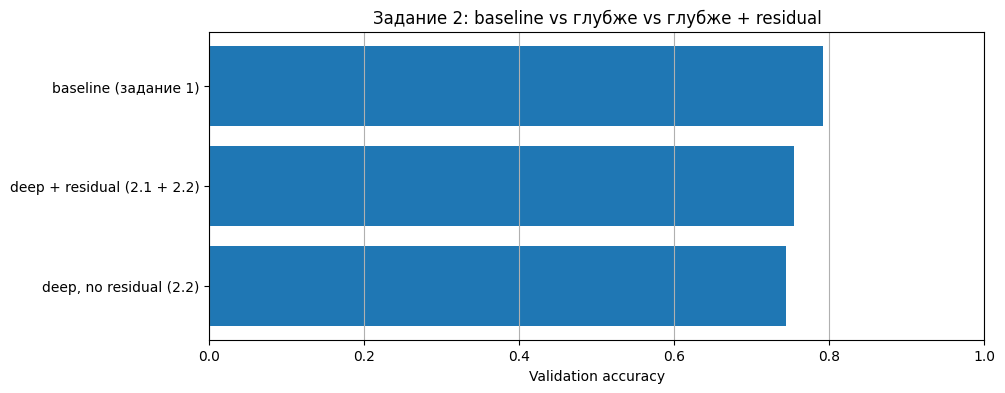

In [ ]:
def last(h, key): return h[key][-1]
def gap(h):       return h["train_acc_eval"][-1] - h["val_acc"][-1]

summary = pd.DataFrame([
    {"model": "baseline (задание 1)",
     "params": sum(p.numel() for p in baseline_model.parameters() if p.requires_grad),
     "train(eval)": last(baseline_hist, "train_acc_eval"),
     "val_acc":     last(baseline_hist, "val_acc"),
     "val_loss":    last(baseline_hist, "val_loss"),
     "gap":         gap(baseline_hist)},
    {"model": "deep, no residual (2.2)",
     "params": sum(p.numel() for p in deep_no_res_model.parameters() if p.requires_grad),
     "train(eval)": last(deep_no_res_hist, "train_acc_eval"),
     "val_acc":     last(deep_no_res_hist, "val_acc"),
     "val_loss":    last(deep_no_res_hist, "val_loss"),
     "gap":         gap(deep_no_res_hist)},
    {"model": "deep + residual (2.1 + 2.2)",
     "params": sum(p.numel() for p in deep_res_model.parameters() if p.requires_grad),
     "train(eval)": last(deep_res_hist, "train_acc_eval"),
     "val_acc":     last(deep_res_hist, "val_acc"),
     "val_loss":    last(deep_res_hist, "val_loss"),
     "gap":         gap(deep_res_hist)},
]).round(4).sort_values("val_acc", ascending=False)

display(summary)

plt.figure(figsize=(10, 4))
plt.barh(summary["model"], summary["val_acc"])
plt.xlim(0, 1)
plt.xlabel("Validation accuracy")
plt.title("Задание 2: baseline vs глубже vs глубже + residual")
plt.gca().invert_yaxis()
plt.grid(True, axis="x")
plt.show()

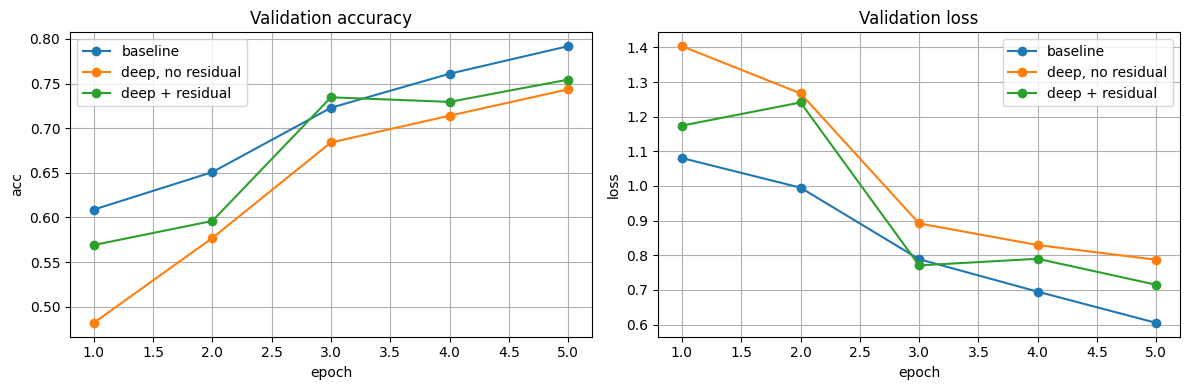

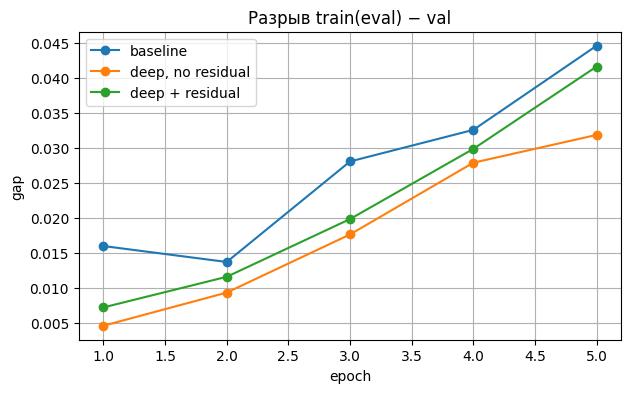

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, h in [("baseline", baseline_hist),
                ("deep, no residual", deep_no_res_hist),
                ("deep + residual",   deep_res_hist)]:
    plt.plot(h["epoch"], h["val_acc"], marker="o", label=name)
plt.title("Validation accuracy")
plt.xlabel("epoch"); plt.ylabel("acc"); plt.grid(True); plt.legend()

plt.subplot(1, 2, 2)
for name, h in [("baseline", baseline_hist),
                ("deep, no residual", deep_no_res_hist),
                ("deep + residual",   deep_res_hist)]:
    plt.plot(h["epoch"], h["val_loss"], marker="o", label=name)
plt.title("Validation loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.grid(True); plt.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
for name, h in [("baseline", baseline_hist),
                ("deep, no residual", deep_no_res_hist),
                ("deep + residual",   deep_res_hist)]:
    gaps = [a - b for a, b in zip(h["train_acc_eval"], h["val_acc"])]
    plt.plot(h["epoch"], gaps, marker="o", label=name)
plt.title("Разрыв train(eval) − val")
plt.xlabel("epoch"); plt.ylabel("gap"); plt.grid(True); plt.legend()
plt.show()

Residual-обход при фиксированной глубине улучшает все ключевые метрики одновременно, причём наибольший эффект виден в начале обучения. в то же время более глубокая сеть без residual при 5 эпохах проигрывает baseline (задание 1), так как увеличение глубины само по себе не гарантирует рост качества, особенно при коротком обучении, но за 5 эпох residual не позволяют глубокой сети обогнать оптимизированный baseline.

все


In [ ]:
class NetC(nn.Module):

    def __init__(self, output_dim, input_dim=1):
        super(NetC, self).__init__()
        self.dp_one = nn.Dropout(0.2)
        self.dp_two = nn.Dropout(0.2)

        self.bn_one1 = torch.nn.BatchNorm2d(input_dim)
        self.bn_one2 = torch.nn.BatchNorm2d(30)
        self.conv_one1 = torch.nn.Conv2d(input_dim, 30, 3, padding=1)#30
        self.conv_one2 = torch.nn.Conv2d(30, 30, 3)#30
        self.bn_two = torch.nn.BatchNorm2d(30)
        self.conv_two1 = torch.nn.Conv2d(30, 30, 3, padding=1)#
        self.conv_two2 = torch.nn.Conv2d(30, 30, 3, padding=1)
        self.conv_two3 = torch.nn.Conv2d(30, 60, 3)

        self.bn_three = torch.nn.BatchNorm2d(60)
        self.conv_three = torch.nn.Conv2d(60, 120, 3)
        self.bn_four = torch.nn.BatchNorm2d(120)
        self.fc1 = torch.nn.Linear(120, 200)
        self.fc2 = torch.nn.Linear(200, 60)
        self.out = torch.nn.Linear(60, output_dim)

    def forward(self, x):
        x1 = self.bn_one1(x)# 28x28x3
        x = x1
        # стек сверток
        x = self.conv_one1(x)#26x26x30
        x = F.relu(x)

        x = self.conv_one2(x)#26x26x30
        x = F.relu(x)
        x = self.bn_one2(x)

        x2 = x
        x = F.max_pool2d(x, 2)#30x13x13
        x4 = x

        x = self.bn_two(x)
        x3 = x
        x = self.conv_two1(x)#60 x 11x11
        x = F.relu(x)
        x = self.conv_two2(x)#60 x 11x11
        x = F.relu(x)
        x = x + x3 # резидуальный обход
        x = self.conv_two3(x)#60 x 11x11
        x = F.relu(x)
        x = F.max_pool2d(x, 2)#60 x 5 x 5

        x = self.bn_three(x)
        x = self.conv_three(x)#120 x 3 x 3
        x = F.leaky_relu(x, 0.1)
        x5 = x
        x = F.max_pool2d(x, 2) #120 x 1 x 1

        x = self.bn_four(x)
        x = x.view(x.size(0), -1) # 120 x 1

        x = self.dp_one(x)
        # print(x.shape)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dp_two(x)
        x = self.fc2(x)
        x = F.relu(x)
        return self.out(x), x1, x2, x3, x4, x5

net = NetC(output_dim=10, input_dim=3).to(device)
print(net)
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)

NetC(
  (dp_one): Dropout(p=0.2, inplace=False)
  (dp_two): Dropout(p=0.2, inplace=False)
  (bn_one1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn_one2): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_one1): Conv2d(3, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_one2): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1))
  (bn_two): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_two1): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_two2): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_two3): Conv2d(30, 60, kernel_size=(3, 3), stride=(1, 1))
  (bn_three): BatchNorm2d(60, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv_three): Conv2d(60, 120, kernel_size=(3, 3), stride=(1, 1))
  (bn_four): BatchNorm2d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1

In [ ]:
num_epochs = 5
net.train()

for epoch in range(num_epochs):
    running_loss, running_items, running_right = 0.0, 0.0, 0.0
    for i, data in enumerate(train_loader):
        inputs, labels = data[0].to(device), data[1].to(device)

        # обнуляем градиент
        optimizer.zero_grad()

        outputs, _,_,_,_,_ = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # выводим статистику о процессе обучения
        running_loss += loss.item()
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum()

        # выводим статистику о процессе обучения
        if i % 300 == 0:    # печатаем каждые 300 mini-batches
            net.eval()

            print(f'Epoch [{epoch + 1}/{num_epochs}]. ' \
                  f'Step [{i + 1}/{len(train_loader)}]. ' \
                  f'Loss: {running_loss / running_items:.3f}. ' \
                  f'Acc: {running_right / running_items:.3f}', end='. ')
            running_loss, running_items, running_right = 0.0, 0.0, 0.0

            test_running_right, test_running_total = 0.0, 0.0
            for i, data in enumerate(test_loader):

                test_outputs, x1,x2,x3,x4,x5 = net(data[0].to(device))
                test_running_total += len(data[1])
                test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum()

            print(f'Test acc: {test_running_right / test_running_total:.3f}')

        mlp.train()

print('Training is finished!')

RuntimeError: mat1 and mat2 shapes cannot be multiplied (128x480 and 120x200)

## Аугментация





In [ ]:
transfor_rgb = torchvision.transforms.Compose([transforms.Resize(224),
                                               transforms.RandomPerspective(distortion_scale=0.6, p=0.50),

                                       transforms.ToTensor(),
                                       transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                                            std=[0.229, 0.224, 0.225])])
batch_size_test = 8
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transfor_rgb)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size_test,
                                         shuffle=False)

In [ ]:
im.min()

In [ ]:
for data in test_loader:
    break

n, k = 4, batch_size_test // 4 + 1 * int((batch_size_test % 4)>0)
images = data[0].cpu().numpy()
labels = data[1].cpu().numpy()
fig, ax = plt.subplots(k, n, figsize=(n*4, 4*k))
for ki in range(k):
    for ni in range(n):
        try:
            im = images[ni + ki*4, :,  :,:].transpose([1,2,0] ) * 0.5 + 0.5
            label = labels[ni + ki*4]
            ax[ki, ni].imshow(im)
            ax[ki, ni].set_title(str(label))
        except:
            pass

## Задание 3

3.1. Сделать аугментации данных

3.2. провести обучение на аугментированных данных

## Исследование по варианту

Выполните один вариант в соответствии с номером в списке группы.

**Вариант 1. Горизонтальное отражение.** Сравните отсутствие отражения и `RandomHorizontalFlip` с вероятностями 0.25 и 0.5. Объясните, почему допустимость преобразования зависит от задачи и можно ли автоматически переносить такой выбор с CIFAR10 на распознавание цифр.

**Вариант 2. Случайный сдвиг и обрезка.** После приведения изображения к 28×28 сравните отсутствие обрезки и `RandomCrop(28, padding=p)` при `p = 2, 4`. Покажите, какие части изображения могут теряться. Объясните компромисс между устойчивостью к положению объекта и потерей полезной информации.

**Вариант 3. Яркость и контраст.** Сравните отсутствие преобразования и `ColorJitter(brightness=a, contrast=a)` при `a = 0.1, 0.3`; насыщенность и оттенок не меняйте. Объясните, какие изменения условий съёмки моделирует этот опыт и почему более сильная аугментация не обязана давать лучший результат.



In [ ]:
import torchvision.transforms as transforms

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

def make_train_transform(brightness_contrast=0.0):
    if brightness_contrast > 0:
        return transforms.Compose([
            transforms.ToTensor(),
            transforms.ColorJitter(brightness=brightness_contrast,
                                   contrast=brightness_contrast,
                                   saturation=0.0, hue=0.0),
            transforms.Normalize(mean=mean, std=std),
        ])
    return transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class: frog


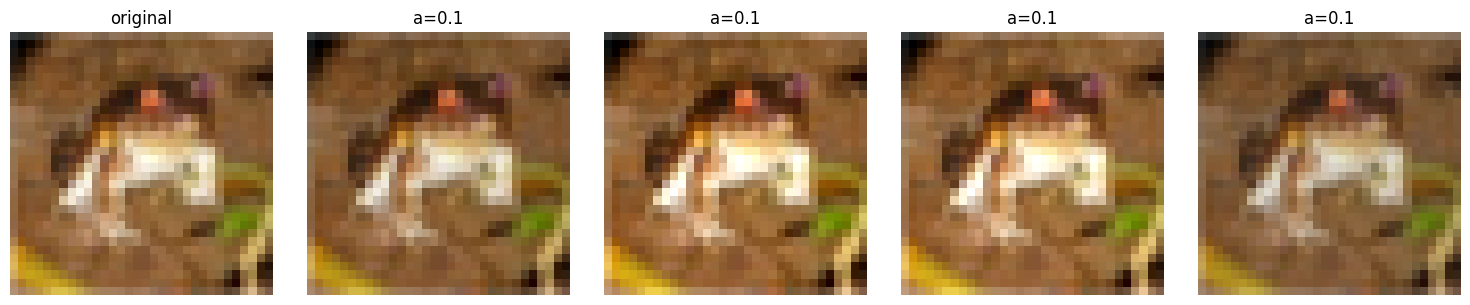

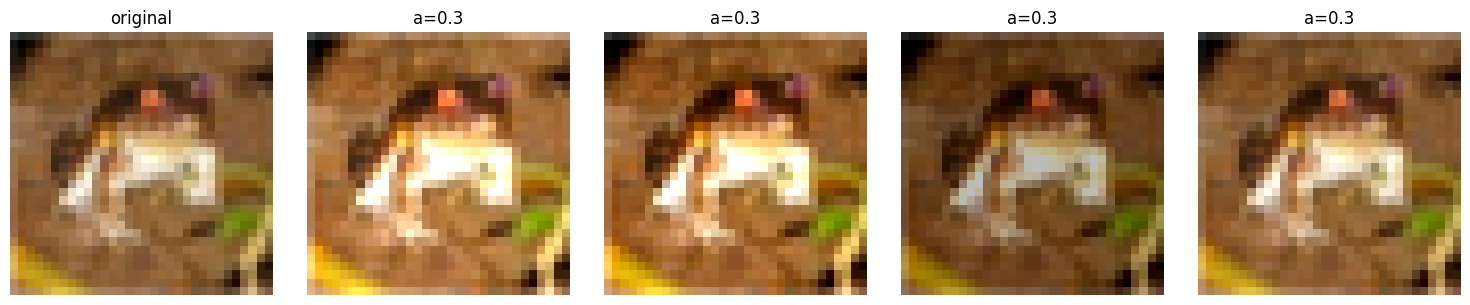

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

raw_cifar = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=False,
    transform=None
)

def apply_jitter_and_show(base_img, a, n=4):
    jitter = transforms.Compose([
        transforms.ToTensor(),
        transforms.ColorJitter(brightness=a, contrast=a,
                               saturation=0.0, hue=0.0),
    ])
    fig, axes = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 3))
    axes[0].imshow(base_img)
    axes[0].set_title("original"); axes[0].axis("off")
    for i in range(n):
        t = jitter(base_img)              # Tensor [0,1]
        axes[i + 1].imshow(t.permute(1, 2, 0).numpy())
        axes[i + 1].set_title(f"a={a}"); axes[i + 1].axis("off")
    plt.tight_layout(); plt.show()

img, label = raw_cifar[0]
print("class:", raw_cifar.classes[label])
apply_jitter_and_show(img, 0.1, n=4)
apply_jitter_and_show(img, 0.3, n=4)

In [ ]:
from torch.utils.data import DataLoader, Subset

def build_loaders(brightness_contrast, seed=42, batch_size=128,
                  num_workers=2, max_train=None):
    set_seed(seed)

    train_ds = torchvision.datasets.CIFAR10(
        root="./data", train=True, download=False,
        transform=make_train_transform(brightness_contrast)
    )
    if max_train is not None:
        g = torch.Generator().manual_seed(seed)
        idx = torch.randperm(len(train_ds), generator=g)[:max_train].tolist()
        train_ds = Subset(train_ds, idx)

    test_ds = torchvision.datasets.CIFAR10(
        root="./data", train=False, download=False,
        transform=transform_test
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=True)
    train_eval_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False,
                                   num_workers=num_workers, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=True)

    return train_loader, train_eval_loader, test_loader, train_ds

In [ ]:
def train_with_loaders(model, train_loader, train_eval_loader, test_loader,
                       name="model", epochs=EPOCHS, lr=1e-3, seed=42):
    set_seed(seed)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {
        "epoch": [], "train_loss": [], "train_acc": [],
        "train_loss_eval": [], "train_acc_eval": [],
        "val_loss": [], "val_acc": [],
    }

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        tr_le, tr_ae = evaluate(model, train_eval_loader)
        va_le, va_ae = evaluate(model, test_loader)

        hist["epoch"].append(epoch)
        hist["train_loss"].append(tr_loss)
        hist["train_acc"].append(tr_acc)
        hist["train_loss_eval"].append(tr_le)
        hist["train_acc_eval"].append(tr_ae)
        hist["val_loss"].append(va_le)
        hist["val_acc"].append(va_ae)

        print(f"[{name}] ep {epoch:02d}/{epochs} | "
              f"train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} | "
              f"train_eval_acc={tr_ae:.4f} | "
              f"val_loss={va_le:.4f} val_acc={va_ae:.4f}")

    return model, hist

In [ ]:
variants = [
    ("no_aug",      0.0),
    ("a=0.1",       0.1),
    ("a=0.3",       0.3),
]

task3_results   = []
task3_histories = {}
task3_models    = {}

for name, a in variants:
    print("\n" + "=" * 80)
    print(f"Вариант: {name}")
    print("=" * 80)

    train_loader_, train_eval_loader_, test_loader_, _ = build_loaders(
        brightness_contrast=a, seed=42, batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS, max_train=MAX_TRAIN_SAMPLES
    )

    model = CIFARCNN(pool_type="max", use_bn=True,
                     dropout_p=0.2, stack_conv=True)

    model, hist = train_with_loaders(
        model, train_loader_, train_eval_loader_, test_loader_,
        name=name, epochs=EPOCHS, seed=42
    )

    task3_models[name]    = model
    task3_histories[name] = hist

    task3_results.append({
        "variant": name,
        "brightness_contrast": a,
        "train_acc_eval": hist["train_acc_eval"][-1],
        "val_acc": hist["val_acc"][-1],
        "gap": hist["train_acc_eval"][-1] - hist["val_acc"][-1],
        "val_loss": hist["val_loss"][-1],
    })

import pandas as pd
task3_df = pd.DataFrame(task3_results).round(4)
display(task3_df.sort_values("brightness_contrast"))


Вариант: no_aug
[no_aug] ep 01/5 | train_loss=1.3276 train_acc=0.5101 | train_eval_acc=0.6390 | val_loss=1.0420 val_acc=0.6276
[no_aug] ep 02/5 | train_loss=0.9408 train_acc=0.6640 | train_eval_acc=0.6298 | val_loss=1.1739 val_acc=0.6159
[no_aug] ep 03/5 | train_loss=0.7782 train_acc=0.7248 | train_eval_acc=0.7408 | val_loss=0.7970 val_acc=0.7187
[no_aug] ep 04/5 | train_loss=0.6703 train_acc=0.7659 | train_eval_acc=0.7866 | val_loss=0.7113 val_acc=0.7528
[no_aug] ep 05/5 | train_loss=0.5921 train_acc=0.7961 | train_eval_acc=0.7806 | val_loss=0.7711 val_acc=0.7389

Вариант: a=0.1
[a=0.1] ep 01/5 | train_loss=1.3338 train_acc=0.5071 | train_eval_acc=0.6451 | val_loss=1.0145 val_acc=0.6301
[a=0.1] ep 02/5 | train_loss=0.9396 train_acc=0.6636 | train_eval_acc=0.6714 | val_loss=0.9876 val_acc=0.6540
[a=0.1] ep 03/5 | train_loss=0.7801 train_acc=0.7232 | train_eval_acc=0.7325 | val_loss=0.7993 val_acc=0.7132
[a=0.1] ep 04/5 | train_loss=0.6743 train_acc=0.7641 | train_eval_acc=0.7172 | val

,variant,brightness_contrast,train_acc_eval,val_acc,gap,val_loss
0,no_aug,0.0,0.7806,0.7389,0.0417,0.7711
1,a=0.1,0.1,0.8105,0.7688,0.0417,0.6612
2,a=0.3,0.3,0.7358,0.7113,0.0245,0.8411


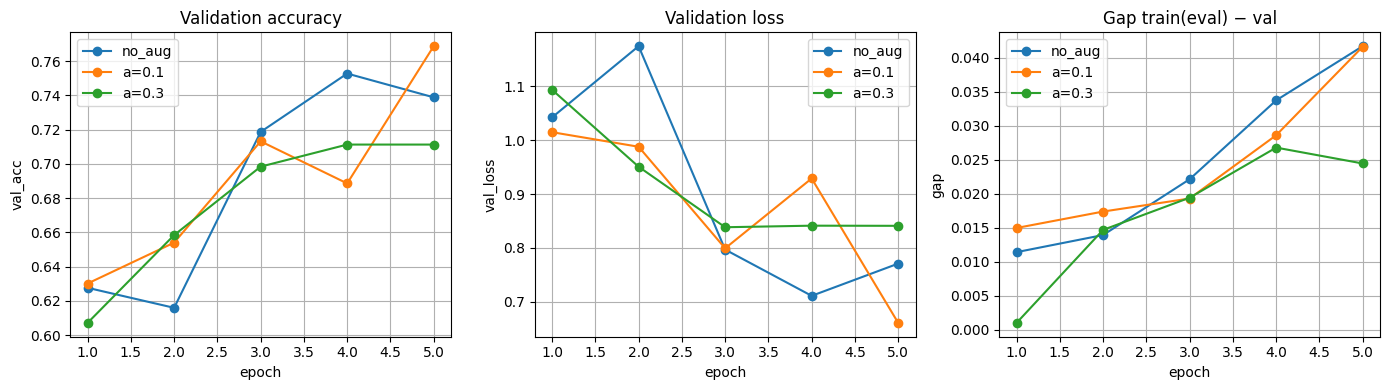

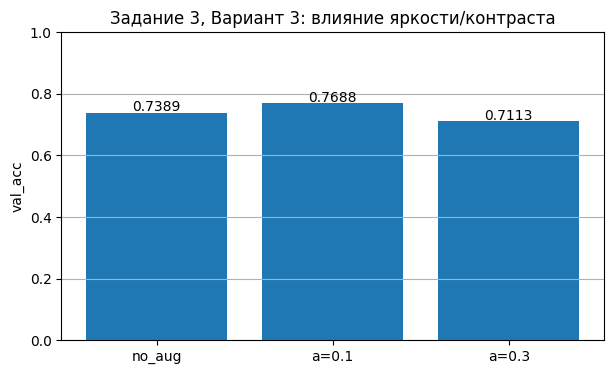

In [ ]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
for name, h in task3_histories.items():
    plt.plot(h["epoch"], h["val_acc"], marker="o", label=name)
plt.title("Validation accuracy")
plt.xlabel("epoch"); plt.ylabel("val_acc"); plt.grid(True); plt.legend()

plt.subplot(1, 3, 2)
for name, h in task3_histories.items():
    plt.plot(h["epoch"], h["val_loss"], marker="o", label=name)
plt.title("Validation loss")
plt.xlabel("epoch"); plt.ylabel("val_loss"); plt.grid(True); plt.legend()

plt.subplot(1, 3, 3)
for name, h in task3_histories.items():
    gaps = [a - b for a, b in zip(h["train_acc_eval"], h["val_acc"])]
    plt.plot(h["epoch"], gaps, marker="o", label=name)
plt.title("Gap train(eval) − val")
plt.xlabel("epoch"); plt.ylabel("gap"); plt.grid(True); plt.legend()

plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
x = task3_df["variant"]
plt.bar(x, task3_df["val_acc"])
plt.ylim(0, 1)
plt.ylabel("val_acc")
plt.title("Задание 3, Вариант 3: влияние яркости/контраста")
for i, v in enumerate(task3_df["val_acc"]):
    plt.text(i, v + 0.005, f"{v:.4f}", ha="center")
plt.grid(True, axis="y")
plt.show()

мягкая аугментация a = 0.1 улучшает все метрики одновременно, причём val_acc растёт монотонно до 5-й эпохи, тогда как без аугментации уже на 5-й эпохе начинается падение — первый признак переобучения, а сильная аугментация a = 0.3, наоборот, ухудшает результат относительно отсутствия аугментации, и её маленький gap — это артефакт недообучения: модель плохо выучила и train, и val, что в сумме говорит: ColorJitter работает в узком диапазоне силы, а маленький gap — это индикатор переобучения




## Резюме

- Свертка определяет локальные окрестности
- Пулинг агрегирует локальные окрестности


## Домашнее задание

База

  1. в обучить нейронный сверточный классификатор (3 сверточных слоя с ядром kxk (relu), MaxPooling((2,2)), полносвязный слой 100 нейронов (relu), выходной слой softMax - 10 нейронов) на  fasion-mnist и посмотреть как будет изменяться результат обработки для ядра 3х3, 5х5 с визуализацией выходов каждого слоя (для одного примера).
  2. Оценить размеры выходов в режиме padding=1, 2.

*
  1. Предложить постановку задачи, где слой усреднения может работать лучше , чем слой максимизации


## Исследование по варианту

Выполните один вариант в соответствии с номером в списке группы.

**Вариант 1. Ошибки по классам.** Постройте матрицу ошибок и найдите две наиболее частые направленные ошибки «истинный класс → предсказанный класс» вне диагонали. Для каждой укажите число ошибок и долю среди объектов истинного класса. Покажите до трёх ошибочно классифицированных изображений для каждой пары, подпишите истинный и предсказанный классы. Объясните возможные причины путаницы и почему общей accuracy недостаточно для такого анализа.

**Вариант 2. Устойчивость к сдвигу.** Сравните предсказания на исходных изображениях и на тех же изображениях, сдвинутых вправо на 2 и 4 пикселя. Сохраняйте размер 28×28: освобождённые пиксели заполняйте нулём до нормализации, вышедшую за границу часть обрезайте, циклический перенос не используйте. Для каждого сдвига укажите accuracy и долю изображений, на которых изменился предсказанный класс. Покажите несколько примеров и объясните, гарантирует ли pooling неизменность ответа при сдвиге.

**Вариант 3. Закрытие части изображения.** Сравните исходные изображения и те же изображения с закрытым центральным квадратом 6×6 и 10×10. Во всех случаях заменяйте пиксели квадрата нулями до нормализации. Сравните accuracy и долю изменившихся предсказанных классов; покажите несколько примеров. Объясните, как потеря центральной части влияет на ответы и почему этот опыт сам по себе не доказывает, какие признаки использует сеть.

  Ссылки:




- Сверточные сети
http://www.deeplearningbook.org/contents/convnets.html
http://www.deeplearningbook.org/contents/optimization.html

- Визуализация сверток
https://gist.github.com/akiross/754c7b87a2af8603da78b46cdaaa5598

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device =", device)

EPOCHS = 5
BATCH_SIZE = 128
NUM_WORKERS = 2
MAX_TRAIN_SAMPLES = None

device = cuda


In [ ]:
mnist_mean, mnist_std = (0.2860,), (0.3530,)

transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mnist_mean, mnist_std),
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mnist_mean, mnist_std),
])

train_ds_full = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform_train)
test_ds = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform_test)

if MAX_TRAIN_SAMPLES is not None:
    g = torch.Generator().manual_seed(42)
    idx = torch.randperm(len(train_ds_full), generator=g)[:MAX_TRAIN_SAMPLES].tolist()
    train_ds = Subset(train_ds_full, idx)
else:
    train_ds = train_ds_full

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
train_eval_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

classes = train_ds_full.classes
print("train:", len(train_ds), "test:", len(test_ds))
print(classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.3MB/s]

train: 60000 test: 10000
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10, kernel_size=3, padding=1):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size, padding=padding)
        self.conv2 = nn.Conv2d(32, 64, kernel_size, padding=padding)
        self.conv3 = nn.Conv2d(64, 128, kernel_size, padding=padding)
        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(128, 100)
        self.fc2 = nn.Linear(100, num_classes)

    def forward(self, x, return_features=False):
        feats = []

        x = F.relu(self.conv1(x)); feats.append(("conv1", x))
        x = self.pool(x);          feats.append(("pool1", x))
        x = F.relu(self.conv2(x)); feats.append(("conv2", x))
        x = self.pool(x);          feats.append(("pool2", x))
        x = F.relu(self.conv3(x)); feats.append(("conv3", x))
        x = self.pool(x);          feats.append(("pool3", x))

        x = self.adaptive(x).flatten(1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return (x, feats) if return_features else x


tmp = FashionCNN().to(device)
with torch.no_grad():
    out = tmp(torch.randn(4, 1, 28, 28).to(device))
print("out shape:", tuple(out.shape), "params:",
      sum(p.numel() for p in tmp.parameters()))

out shape: (4, 10) params: 106582


In [ ]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    tl, total, correct = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        tl += loss.item() * x.size(0)
        total += x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
    return tl / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    tl, total, correct = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        tl += loss.item() * x.size(0)
        total += x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
    return tl / total, correct / total


def train_model(model, name, epochs=EPOCHS, lr=1e-3, seed=42):
    set_seed(seed)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"epoch": [], "train_loss": [], "train_acc": [],
            "train_acc_eval": [], "val_loss": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        tr_l, tr_a = train_one_epoch(model, train_loader, opt)
        _, tr_ae = evaluate(model, train_eval_loader)
        va_l, va_a = evaluate(model, test_loader)
        hist["epoch"].append(ep)
        hist["train_loss"].append(tr_l)
        hist["train_acc"].append(tr_a)
        hist["train_acc_eval"].append(tr_ae)
        hist["val_loss"].append(va_l)
        hist["val_acc"].append(va_a)
        print(f"[{name}] ep {ep:02d}/{epochs} | "
              f"train_loss={tr_l:.4f} train_acc={tr_a:.4f} | "
              f"train_eval_acc={tr_ae:.4f} | "
              f"val_loss={va_l:.4f} val_acc={va_a:.4f}")
    return model, hist

In [ ]:
kernels = [3, 5]
models, histories, results = {}, {}, []

for k in kernels:
    print("\n" + "=" * 70)
    print(f"kernel_size = {k}, padding = {k // 2}")
    print("=" * 70)
    m = FashionCNN(kernel_size=k, padding=k // 2)
    m, h = train_model(m, name=f"k={k}", epochs=EPOCHS)
    models[k], histories[k] = m, h
    results.append({
        "kernel": k,
        "padding": k // 2,
        "params": sum(p.numel() for p in m.parameters()),
        "train(eval)": h["train_acc_eval"][-1],
        "val_acc": h["val_acc"][-1],
        "val_loss": h["val_loss"][-1],
        "gap": h["train_acc_eval"][-1] - h["val_acc"][-1],
    })

display(pd.DataFrame(results).round(4))


kernel_size = 3, padding = 1
[k=3] ep 01/5 | train_loss=0.7756 train_acc=0.7148 | train_eval_acc=0.7995 | val_loss=0.5669 val_acc=0.7908
[k=3] ep 02/5 | train_loss=0.4830 train_acc=0.8232 | train_eval_acc=0.8267 | val_loss=0.5040 val_acc=0.8218
[k=3] ep 03/5 | train_loss=0.4046 train_acc=0.8533 | train_eval_acc=0.8743 | val_loss=0.3791 val_acc=0.8605
[k=3] ep 04/5 | train_loss=0.3547 train_acc=0.8723 | train_eval_acc=0.8835 | val_loss=0.3581 val_acc=0.8723
[k=3] ep 05/5 | train_loss=0.3270 train_acc=0.8818 | train_eval_acc=0.8927 | val_loss=0.3301 val_acc=0.8792

kernel_size = 5, padding = 2
[k=5] ep 01/5 | train_loss=0.6805 train_acc=0.7446 | train_eval_acc=0.8257 | val_loss=0.4825 val_acc=0.8181
[k=5] ep 02/5 | train_loss=0.4066 train_acc=0.8505 | train_eval_acc=0.8635 | val_loss=0.3988 val_acc=0.8574
[k=5] ep 03/5 | train_loss=0.3306 train_acc=0.8803 | train_eval_acc=0.8962 | val_loss=0.3211 val_acc=0.8835
[k=5] ep 04/5 | train_loss=0.2944 train_acc=0.8921 | train_eval_acc=0.8998 |

,kernel,padding,params,train(eval),val_acc,val_loss,gap
0,3,1,106582,0.8926,0.8792,0.3301,0.0135
1,5,2,270934,0.9159,0.9012,0.2708,0.0147


Класс: Ankle boot

---- kernel_size = 3 ----


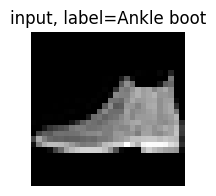

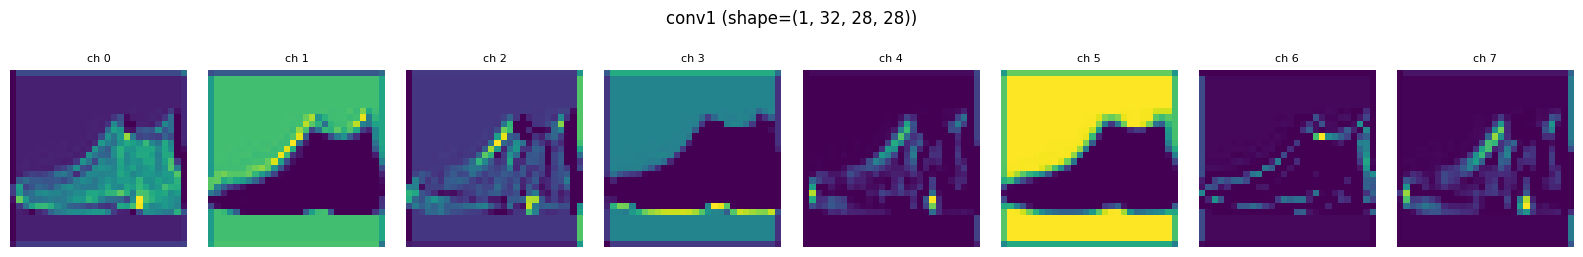

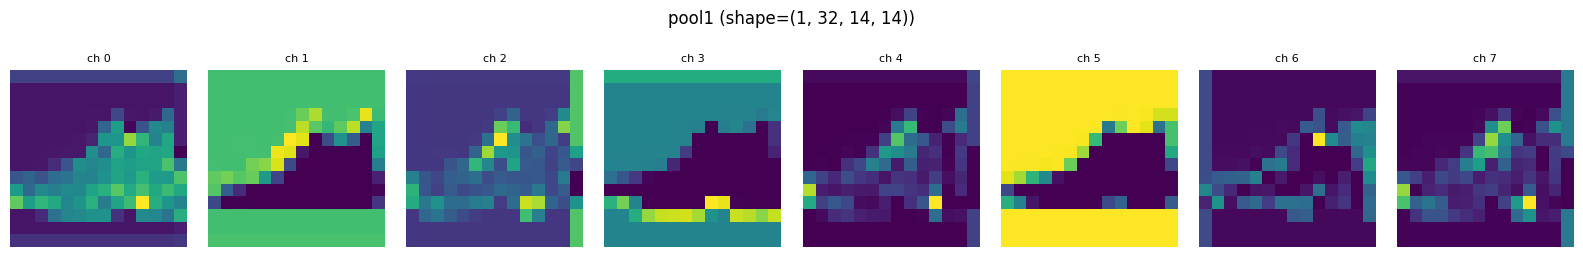

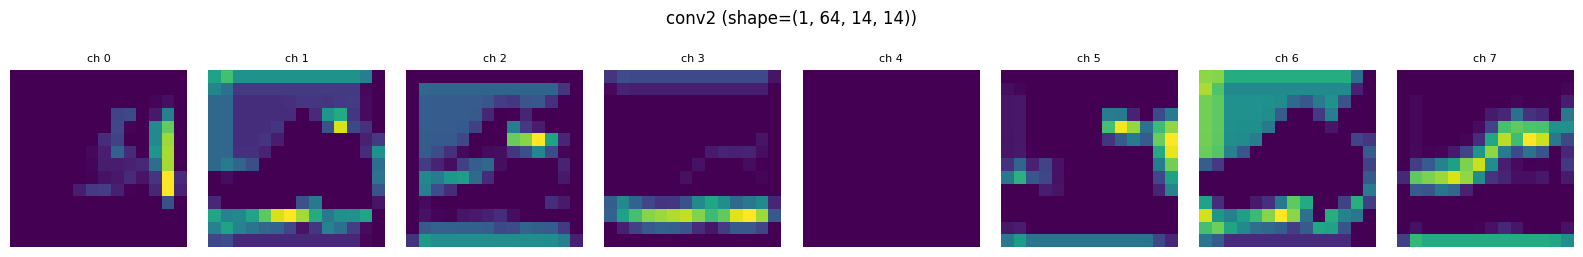

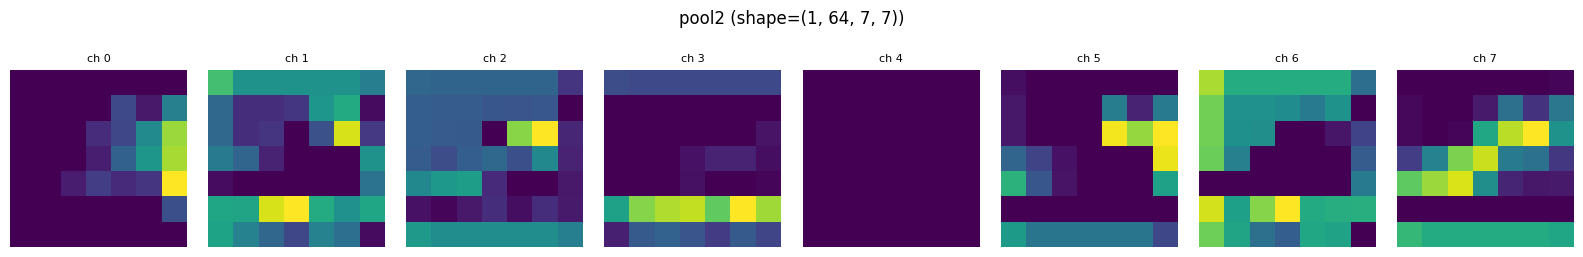

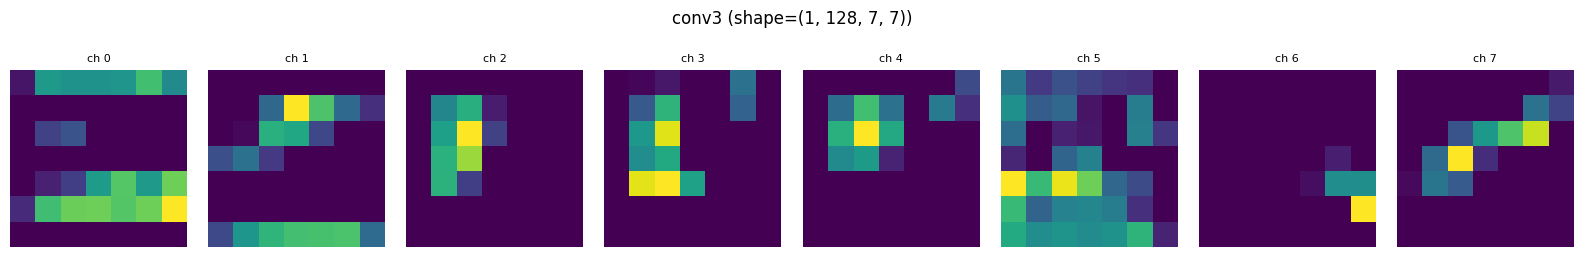

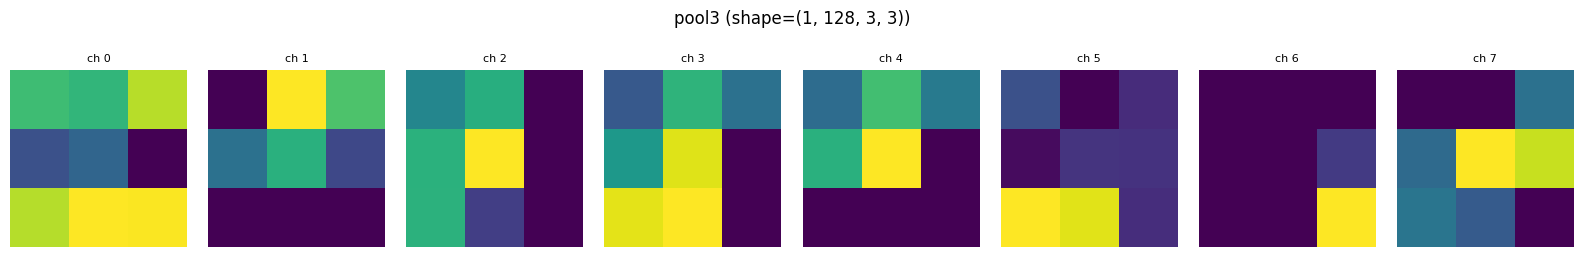


---- kernel_size = 5 ----


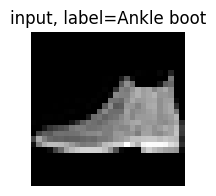

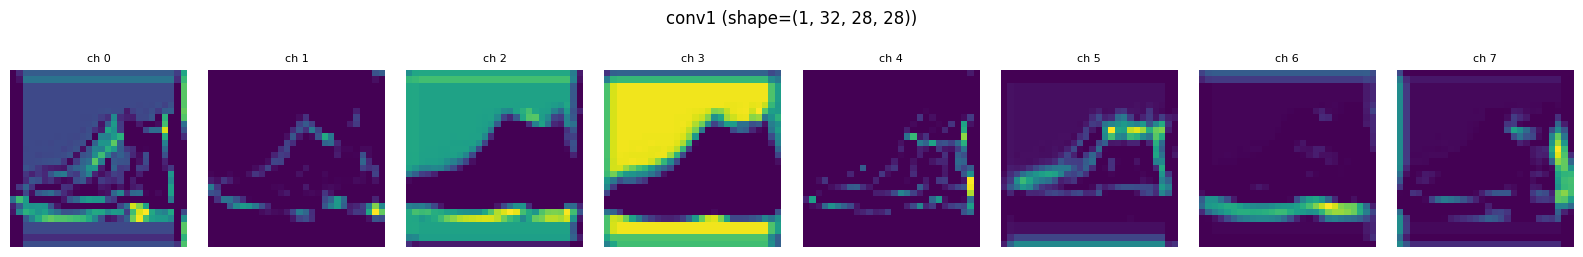

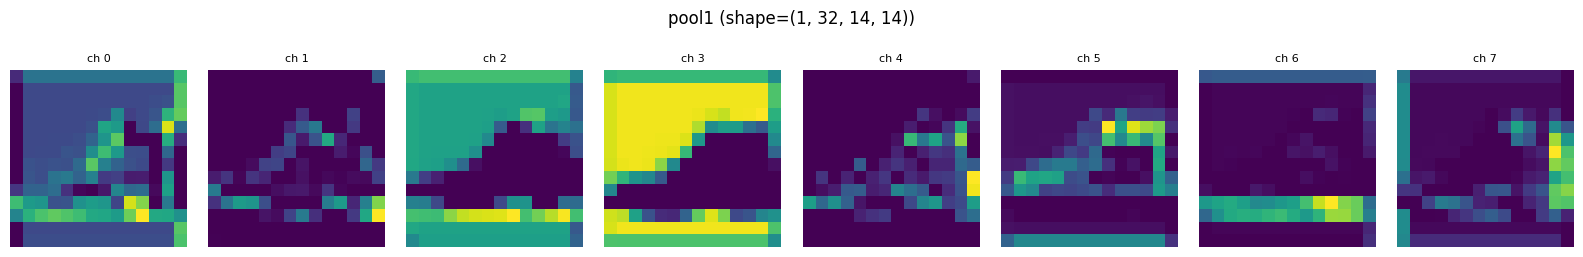

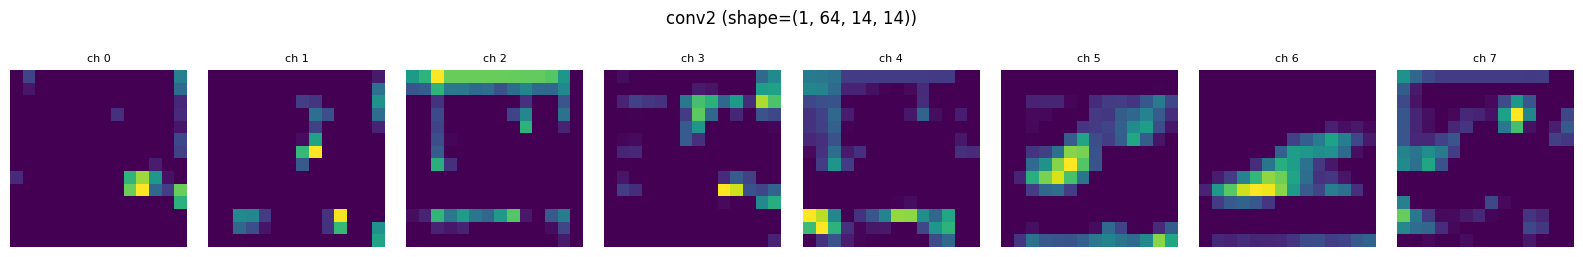

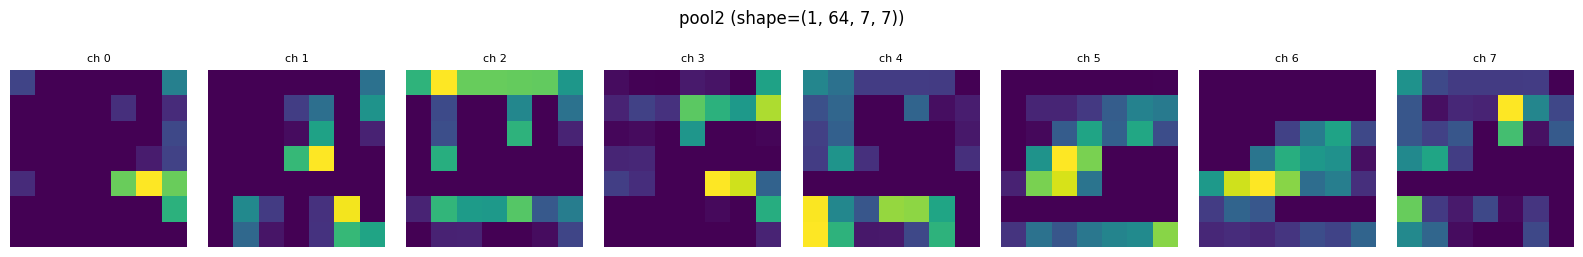

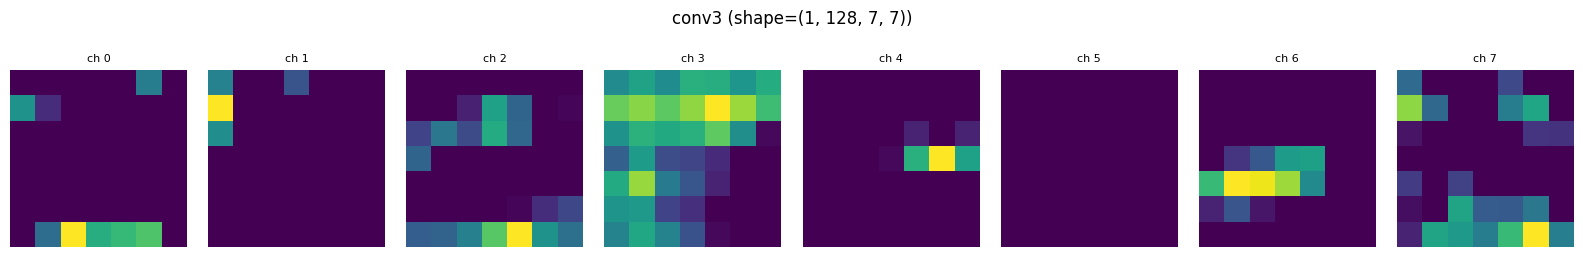

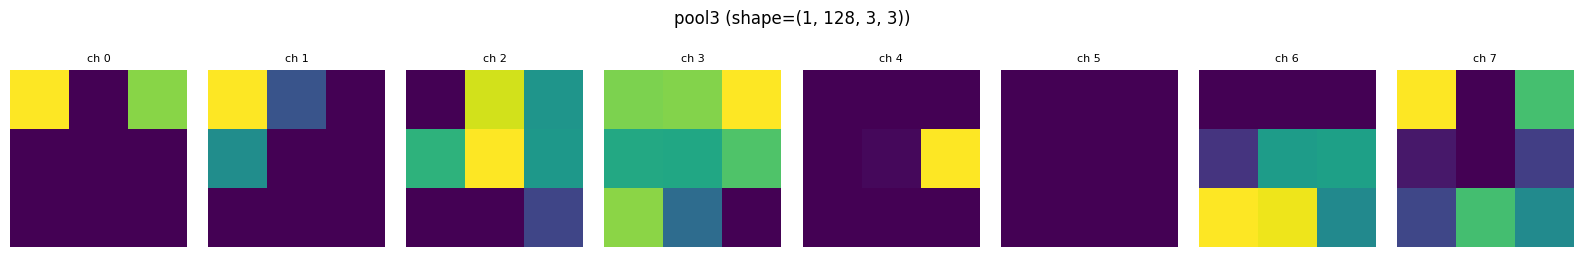

In [ ]:
def plot_layer(feature_map, title, n=8, cmap="viridis"):
    n = min(n, feature_map.shape[1])
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    for i in range(n):
        axes[i].imshow(feature_map[0, i].detach().cpu().numpy(), cmap=cmap)
        axes[i].axis("off")
        axes[i].set_title(f"ch {i}", fontsize=8)
    fig.suptitle(title, y=1.05)
    plt.tight_layout(); plt.show()


def visualize_layers(model, image, label, n=8):
    model.eval()
    with torch.no_grad():
        _, feats = model(image.to(device), return_features=True)

    # исходник (денормализуем)
    img01 = image[0, 0].cpu().numpy() * mnist_std[0] + mnist_mean[0]
    plt.figure(figsize=(2, 2))
    plt.imshow(img01, cmap="gray")
    plt.title(f"input, label={classes[label]}")
    plt.axis("off"); plt.show()

    for name, fm in feats:
        plot_layer(fm, f"{name} (shape={tuple(fm.shape)})", n=n)


# Возьмём одно тестовое изображение
img, label = test_ds[0]
print("Класс:", classes[label])

for k in kernels:
    print(f"\n---- kernel_size = {k} ----")
    visualize_layers(models[k], img.unsqueeze(0), label, n=8)

In [ ]:
def conv_out(in_size, k, p, s=1):
    return (in_size + 2 * p - k) // s + 1

def pool_out(in_size, k=2, s=2):
    return (in_size - k) // s + 1

def trace_sizes(in_size=28, kernel=3, padding=1):
    rows = []
    h = w = in_size
    for i, tag in enumerate(["conv1", "pool1", "conv2", "pool2", "conv3", "pool3"], 1):
        if tag.startswith("conv"):
            h, w = conv_out(h, kernel, padding), conv_out(w, kernel, padding)
        else:
            h, w = pool_out(h), pool_out(w)
        rows.append({"layer": tag, "H": h, "W": w})
    return rows


size_table = []
for k in [3, 5]:
    for p in [1, 2]:
        rows = trace_sizes(28, k, p)
        final = rows[-1]
        size_table.append({
            "kernel": k, "padding": p,
            "conv1_out": rows[0]["H"],
            "pool1_out": rows[1]["H"],
            "conv2_out": rows[2]["H"],
            "pool2_out": rows[3]["H"],
            "conv3_out": rows[4]["H"],
            "pool3_out": f"{final['H']}x{final['W']}",
        })

display(pd.DataFrame(size_table))

print("\nПрактическая проверка через forward:")
for k in [3, 5]:
    for p in [1, 2]:
        m = FashionCNN(kernel_size=k, padding=p).to(device)
        with torch.no_grad():
            _, feats = m(torch.zeros(1, 1, 28, 28).to(device), return_features=True)
        shapes = " → ".join(f"{name}:{tuple(fm.shape[2:])}" for name, fm in feats)
        print(f"k={k}, p={p}: {shapes}")

,kernel,padding,conv1_out,pool1_out,conv2_out,pool2_out,conv3_out,pool3_out
0,3,1,28,14,14,7,7,3x3
1,3,2,30,15,17,8,10,5x5
2,5,1,26,13,11,5,3,1x1
3,5,2,28,14,14,7,7,3x3



Практическая проверка через forward:
k=3, p=1: conv1:(28, 28) → pool1:(14, 14) → conv2:(14, 14) → pool2:(7, 7) → conv3:(7, 7) → pool3:(3, 3)
k=3, p=2: conv1:(30, 30) → pool1:(15, 15) → conv2:(17, 17) → pool2:(8, 8) → conv3:(10, 10) → pool3:(5, 5)
k=5, p=1: conv1:(26, 26) → pool1:(13, 13) → conv2:(11, 11) → pool2:(5, 5) → conv3:(3, 3) → pool3:(1, 1)
k=5, p=2: conv1:(28, 28) → pool1:(14, 14) → conv2:(14, 14) → pool2:(7, 7) → conv3:(7, 7) → pool3:(3, 3)


Визуализация слоёв (k=3 vs k=5, один пример). Прогнали одно изображение через обе модели и построили карты активаций после каждой conv и каждого pool; в ранних conv видны края и градиенты, в глубоких — абстрактные текстуры, у k=5 отклики шире (больше контекста), у k=3 — локальнее, после каждого MaxPool карта уменьшается вдвое и сохраняет самые сильные отклики.

Размеры выходов при padding=1, 2. Анализ совпала с forward: k=3, p=1 - 28-14-14-7-7-3* 3; k=3, p=2 - 30-15-17-8-10-5* 5; k=5, p=1 - 26-13-11-5-3-1* 1; k=5, p=2 - 28-14-14-7-7-3* 3 — то есть padding = k//2 сохраняет размер по conv, а MaxPool(2*2) уменьшает вдвое с округлением вниз.

Слой усреднения может работать лучше максимизации в задаче,
где важен средний уровень сигнала, а не пиковые отклики.

Пример постановки: классификация сцен по уровню освещённости / средней
интенсивности (например, «день / сумерки / ночь» по гистограмме яркости),
или регрессия средней яркости / плотности объектов на изображении.

Почему AvgPool выигрывает:
  • MaxPool сохраняет только пик в каждом окне и теряет информацию о том,
    сколько пикселей в окне были яркими. Для задачи «средняя яркость сцены»
    это критично: максимум в окне одинаков у яркого и тусклого участков,
    если в них есть хотя бы один яркий пиксель (шум, блик).
  • AvgPool сохраняет среднее — то есть именно ту величину, которую мы
    хотим предсказать. Дальнейшие слои получают «честную» оценку
    интенсивности окна.

Конкретный тест: Fashion-MNIST / синтетическое MNIST, где метка — средняя
яркость (например, бинаризация: «яркое» vs «тёмное»). Модель с AvgPool
сойдётся быстрее и даст меньше ошибок, чем с MaxPool.

In [ ]:
def occlude_center_before_norm(images_01, size):
    out = images_01.clone()
    H, W = out.shape[-2], out.shape[-1]
    top = (H - size) // 2
    left = (W - size) // 2
    out[:, :, top:top + size, left:left + size] = 0.0
    return out


raw_test = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=False, transform=transforms.ToTensor()
)

x_raw = torch.stack([raw_test[i][0] for i in range(len(raw_test))])  # [N,1,28,28], [0,1]
y_all = torch.tensor([raw_test[i][1] for i in range(len(raw_test))])
print("raw test:", x_raw.shape, "range:", float(x_raw.min()), float(x_raw.max()))


def normalize_batch(x01, mean, std):
    m = torch.tensor(mean).view(1, -1, 1, 1)
    s = torch.tensor(std).view(1, -1, 1, 1)
    return (x01 - m) / s


def predict_in_batches(model, x, batch=512):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(x), batch):
            logits = model(x[i:i + batch].to(device))
            preds.append(logits.argmax(1).cpu())
    return torch.cat(preds)

raw test: torch.Size([10000, 1, 28, 28]) range: 0.0 1.0


In [ ]:
model_for_occ = models[3]
x_norm_orig = normalize_batch(x_raw, mnist_mean, mnist_std)
pred_orig = predict_in_batches(model_for_occ, x_norm_orig)
acc_orig = (pred_orig == y_all).float().mean().item()

variants = {
    "orig":   None,
    "occ6":   6,
    "occ10":  10,
}

rows = []
preds_by_variant = {"orig": pred_orig}
for name, s in variants.items():
    if s is None:
        continue
    x_occ = occlude_center_before_norm(x_raw, s)
    x_occ_norm = normalize_batch(x_occ, mnist_mean, mnist_std)
    preds = predict_in_batches(model_for_occ, x_occ_norm)
    preds_by_variant[name] = preds

    acc = (preds == y_all).float().mean().item()
    changed = (preds != pred_orig).float().mean().item()
    rows.append({
        "variant": name,
        "accuracy": acc,
        "Δacc vs orig": acc - acc_orig,
        "доля изменившихся предсказаний": changed,
    })

rows.insert(0, {"variant": "orig", "accuracy": acc_orig,
                "Δacc vs orig": 0.0,
                "доля изменившихся предсказаний": 0.0})

occlusion_df = pd.DataFrame(rows).round(4)
display(occlusion_df)

,variant,accuracy,Δacc vs orig,доля изменившихся предсказаний
0,orig,0.8792,0.0000,0.0000
1,occ6,0.7502,-0.1290,0.2219
2,occ10,0.4558,-0.4234,0.5304


Примеры, где occ10 изменил предсказание: [0, 2, 3, 4, 5]


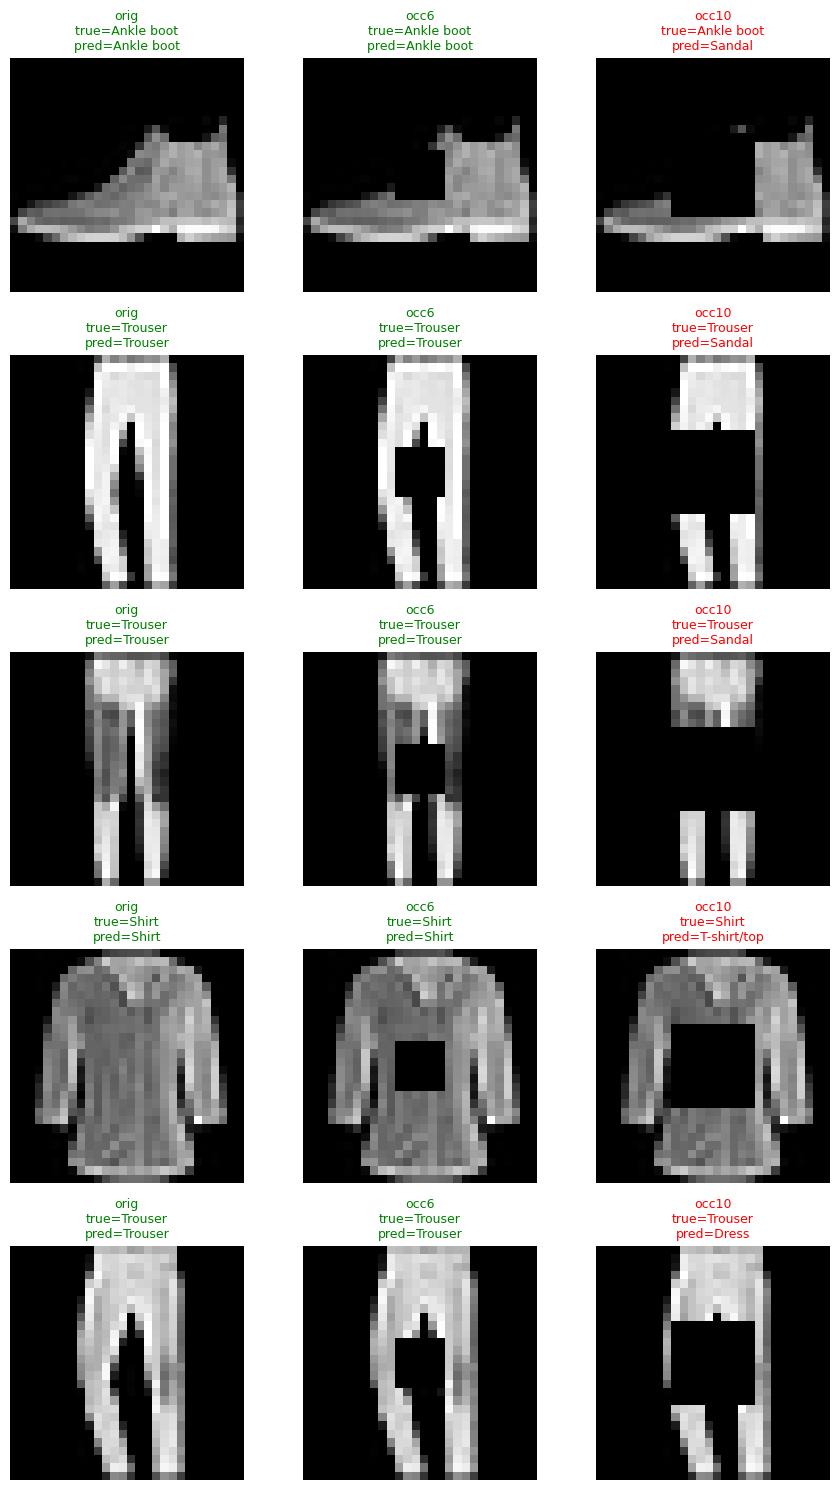

Примеры, где occ10 не изменил предсказание: [1, 8, 10]


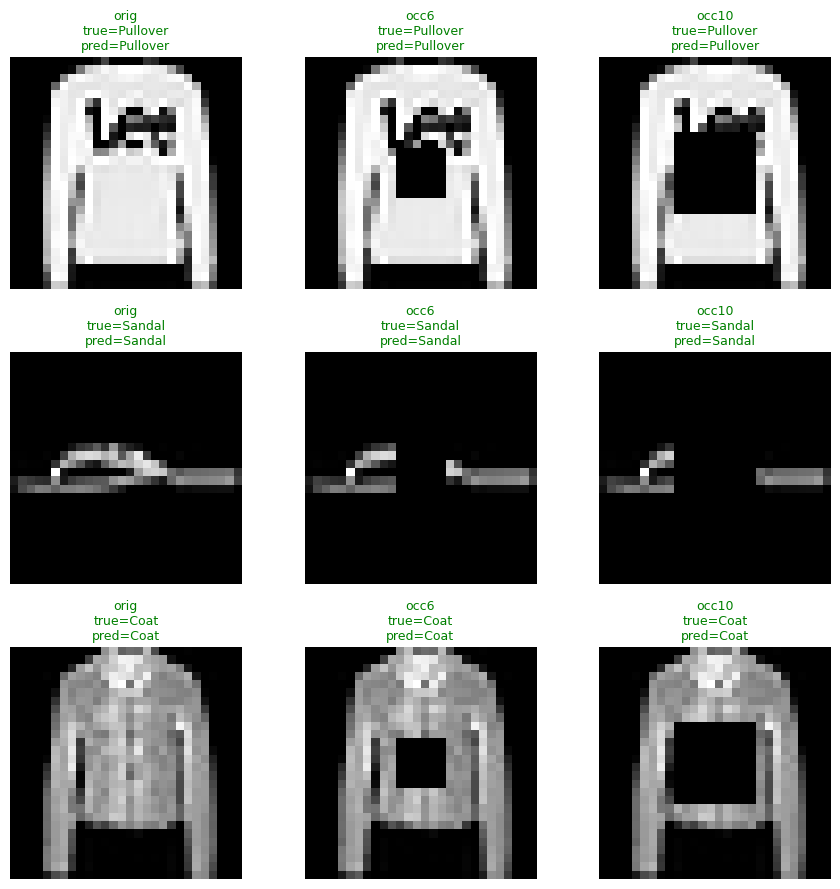

In [ ]:
def show_occlusion_examples(model, x_raw, y_all, pred_orig, preds_by_variant,
                            idxs, mean, std, classes):
    n = len(idxs)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    if n == 1:
        axes = axes[None, :]

    for row, i in enumerate(idxs):
        img01 = x_raw[i, 0].numpy()
        y_true = classes[int(y_all[i])]

        for col, (name, occ_size) in enumerate(
            [("orig", None), ("occ6", 6), ("occ10", 10)]
        ):
            if occ_size is None:
                ax_img = img01
            else:
                tmp = occlude_center_before_norm(
                    x_raw[i:i + 1], occ_size
                )[0, 0].numpy()
                ax_img = tmp

            pred_label = preds_by_variant[name][i].item()
            pred_name = classes[pred_label]
            correct = (pred_label == int(y_all[i]))

            axes[row, col].imshow(ax_img, cmap="gray")
            axes[row, col].axis("off")
            color = "green" if correct else "red"
            axes[row, col].set_title(
                f"{name}\ntrue={y_true}\npred={pred_name}",
                color=color, fontsize=9)

    plt.tight_layout(); plt.show()


changed_occ10 = (preds_by_variant["occ10"] != pred_orig).nonzero(as_tuple=True)[0]
idxs_changed = changed_occ10[:5].tolist()
print("Примеры, где occ10 изменил предсказание:", idxs_changed)

show_occlusion_examples(model_for_occ, x_raw, y_all, pred_orig,
                        preds_by_variant, idxs_changed,
                        mnist_mean, mnist_std, classes)

not_changed = (preds_by_variant["occ10"] == pred_orig).nonzero(as_tuple=True)[0]
idxs_same = not_changed[:3].tolist()
print("Примеры, где occ10 не изменил предсказание:", idxs_same)
show_occlusion_examples(model_for_occ, x_raw, y_all, pred_orig,
                        preds_by_variant, idxs_same,
                        mnist_mean, mnist_std, classes)

На Fashion-MNIST закрытие центрального квадрата резко роняет accuracy, при 53% изменившихся предсказаний для 10* 10 — то есть сеть действительно сильно зависит от центральной области.